# GlowUp Radar - Entrega Final: ¿con qué importador debería firmar Seoru?




## 1. Librerías que vamos a usar

In [63]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files

# Modelos existentes
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Nuevos modelos
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Validación y evaluación
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

## 2. Configuración general del análisis

In [64]:
OBJETIVO = "y_abandona" # 1 si el importador reduce sus importaciones a menos de la mitad en t+1
ANIO_ENTRENAMIENTO = 2023
ANIO_PRUEBA = 2024
ANIO_RADAR = 2025 # No tiene desenlace todavía
K = 5 # Batches para el cross validation
N_BOOTSTRAP = 1000 # Muestras para los intervalos de confianza
SEMILLA = 42 # Para que el análisis salga siempre en el mismo resultado

### 2.1 Cuánto le cuesta a Seoru cada error (US$ por importador)

In [65]:
# Decisiones: 0 = firmar, 1 = firmar con garantías, 2 = no firmar
FIRMAR, GARANTIAS, NO_FIRMAR = 0, 1, 2
NOMBRES = {FIRMAR: "Firmar", GARANTIAS: "Firmar con garantías", NO_FIRMAR: "No firmar"}

# filas = decisión, columnas = lo que pasó (0 = se queda, 1 = abandona)
COSTO = np.array([
    [0, 250000],      # firmar
    [20000, 120000],  # firmar con garantías
    [50000, 0],       # no firmar
])
pd.DataFrame(COSTO, index=NOMBRES.values(), columns=["Se queda", "Abandona"])

,Se queda,Abandona
Firmar,0,250000
Firmar con garantías,20000,120000
No firmar,50000,0


## 3. Subir y leer la base de datos
Al correr la siguiente celda aparece un botón para subir el archivo desde el computador.

In [66]:
# Suban glowup_data.csv de Bloque Neón y el Diccionario_datos.xlsx
uploaded = files.upload()

csv_file = next(name for name in uploaded if name.endswith(".csv"))
datos = pd.read_csv(csv_file)
print("Base de datos cargada:", csv_file)

xlsx_files = [name for name in uploaded if name.endswith(".xlsx")]
if len(xlsx_files) > 0:
    diccionario = pd.read_excel(xlsx_files[0], sheet_name=0, header=2)
    print("Diccionario cargado:", xlsx_files[0])

Saving glowup_data (1).csv to glowup_data (1) (1).csv
Saving Diccionario_datos (1).xlsx to Diccionario_datos (1) (1).xlsx
Base de datos cargada: glowup_data (1) (1).csv
Diccionario cargado: Diccionario_datos (1) (1).xlsx


In [67]:
datos.head()

,nit,cif_t,n_decl_t,n_proveedores_t,n_paises_t,n_meses_activos_t,share_china_t,share_ue_t,share_usa_t,momentum_h2_t,...,yt_img_brillo,yt_img_saturacion,yt_img_rosa,yt_img_colorido,yt_share_relevante,yt_consultado,yt_n_coment,yt_sent_neto,yt_intencion_compra,y_abandona
0,NaN,3916902.61,289,80,12,12,0.305087,0.052285,0.039912,0.463328,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
1,800000946.0,66391776.60,1798,8,7,12,0.001162,0.018379,0.040214,0.560048,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2,800011002.0,2188618.27,68,10,5,12,0.014135,0.010243,0.870755,0.431135,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
3,800018359.0,14916432.62,874,33,14,12,0.026670,0.277611,0.029021,0.530212,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
4,800019615.0,4685351.91,933,77,37,12,0.066295,0.607486,0.050258,0.549001,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0


## 4. Primera mirada a los datos

### 4.1 Cuántas filas e importadores hay

In [68]:
print(datos.shape)
print("Importadores distintos:", datos["nit"].nunique())
datos["anio_t"].value_counts().sort_index()

(1773, 55)
Importadores distintos: 790


,count
anio_t,
2023,574
2024,578
2025,621


### 4.2 Datos faltantes por columna

In [69]:
nulos = pd.DataFrame({
    "nulos": datos.isna().sum(),
    "porcentaje": (datos.isna().mean() * 100).round(1),
})
nulos[nulos["nulos"] > 0].sort_values("nulos", ascending=False)

,nulos,porcentaje
yt_n_coment,1739,98.1
yt_sent_neto,1739,98.1
yt_intencion_compra,1739,98.1
yt_like_rate,1720,97.0
yt_log_views,1720,97.0
yt_canales,1720,97.0
yt_img_brillo,1720,97.0
yt_img_saturacion,1720,97.0
yt_img_colorido,1720,97.0
yt_img_rosa,1720,97.0


- `y_abandona`, `cif_t1`, `ratio_t1`, `y_crece`: vacíos solo en 2025, porque todavía no se sabe qué pasa en 2026.
- `texto_productos_t` (55 %): el importador no notificó productos nuevos ese año. En esos casos las columnas `cat_*` valen 0.
- `yt_*`: solo hay datos de 84 importadores de 2024. No entran al modelo.
- 5 filas sin datos del RUES (`edad_anios_t`, `forma`, `ciiu`): se completan con la mediana de entrenamiento.

### 4.3 Qué porcentaje de importadores abandona (tasa base)

In [70]:
datos.groupby("anio_t")[OBJETIVO].agg(["count", "sum", "mean"]).round(3)

,count,sum,mean
anio_t,,,
2023,574,124.0,0.216
2024,578,113.0,0.196
2025,0,0.0,NaN


## 5. Qué importadores entran al análisis (filtros)

1. Quitamos las filas sin NIT ("PERSONA NATURAL"): no hay una empresa con quien firmar.
2. Dejamos solo importadores de consumo: con registros INVIMA o con actividad de comercio (CIIU 46 o 47). Los fabricantes sin INVIMA importan materia prima y no distribuyen marcas.

In [71]:
conteo = [["Archivo original", len(datos)]]

datos = datos[datos["nit"].notna()].copy()
conteo.append(["Sin filas sin NIT", len(datos)])

ciiu_2_digitos = datos["ciiu_2"].fillna(0).astype(int).astype(str).str[:2]
es_comercio = ciiu_2_digitos.isin(["46", "47"])
datos = datos[(datos["tiene_invima"] == 1) | es_comercio].copy()
conteo.append(["Solo importadores de consumo", len(datos)])

for anio in [ANIO_ENTRENAMIENTO, ANIO_PRUEBA, ANIO_RADAR]:
    conteo.append(["   Año " + str(anio), (datos["anio_t"] == anio).sum()])

pd.DataFrame(conteo, columns=["Paso", "Filas"])

,Paso,Filas
0,Archivo original,1773
1,Sin filas sin NIT,1770
2,Solo importadores de consumo,1540
3,Año 2023,497
4,Año 2024,503
5,Año 2025,540


## 6. Columnas que no podemos usar porque revelan el futuro (detector de fuga)

AUC de cada variable sola en 2023. Si una variable sola ordena casi perfecto (AUC cerca de 0 o de 1), hay que sospechar. Un AUC menor que 0,5 quiere decir que a más valor, menos abandono.

In [72]:
entrenamiento_crudo = datos[datos["anio_t"] == ANIO_ENTRENAMIENTO]
numericas = datos.select_dtypes(include="number").columns.tolist()

filas = []
for col in numericas:
    if col in ["nit", "anio_t", OBJETIVO] or col.startswith("yt_"):
        continue
    tabla = entrenamiento_crudo[[col, OBJETIVO]].dropna()
    if tabla[col].nunique() > 1:
        auc = roc_auc_score(tabla[OBJETIVO], tabla[col])
        filas.append([col, auc, abs(auc - 0.5)])

fuga = pd.DataFrame(filas, columns=["Variable", "AUC", "Fuerza"])
fuga.sort_values("Fuerza", ascending=False).head(10).round(3)

,Variable,AUC,Fuerza
34,ratio_t1,0.000,0.500
33,cif_t1,0.063,0.437
4,n_meses_activos_t,0.263,0.237
1,n_decl_t,0.296,0.204
0,cif_t,0.309,0.191
35,y_crece,0.326,0.174
28,edad_anios_t,0.360,0.140
16,n_fabricantes_t,0.397,0.103
2,n_proveedores_t,0.402,0.098
11,reg_t,0.403,0.097


`ratio_t1` y `cif_t1` describen el año siguiente: son fuga y se excluyen, junto con `y_crece` (target alterno). Las variables legítimas más fuertes son los meses activos, el número de declaraciones y el valor importado, y ninguna separa perfecto.

**Columnas que no entran al modelo:**
- Fuga: `cif_t1`, `ratio_t1`
- Targets: `y_abandona`, `y_crece`
- Identificadores: `nit`, `anio_t`
- Contexto: `razon_social`, `n_grafias_razon`, `tiene_invima` (ya se usó en el filtro), `yt_*`
- Texto: `texto_productos_t` (se convierte en la variable de afinidad)

## 7. Qué diferencia a los importadores que abandonan

### 7.1 Cuánto importa cada importador al año

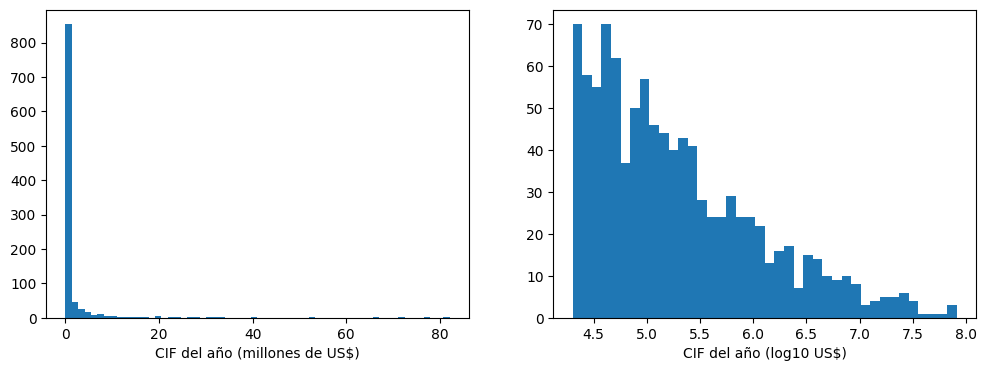

In [73]:
con_desenlace = datos[datos["anio_t"] < ANIO_RADAR].copy()

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].hist(con_desenlace["cif_t"] / 1e6, bins=60)
ejes[0].set_xlabel("CIF del año (millones de US$)")
ejes[1].hist(np.log10(con_desenlace["cif_t"]), bins=40)
ejes[1].set_xlabel("CIF del año (log10 US$)")
plt.show()

La mayoría importa poco (mediana cercana a US$130 mil) y unos pocos traen decenas de millones. Por eso usamos el valor en logaritmo.

### 7.2 Abandono según constancia, tamaño, antigüedad, origen y productos

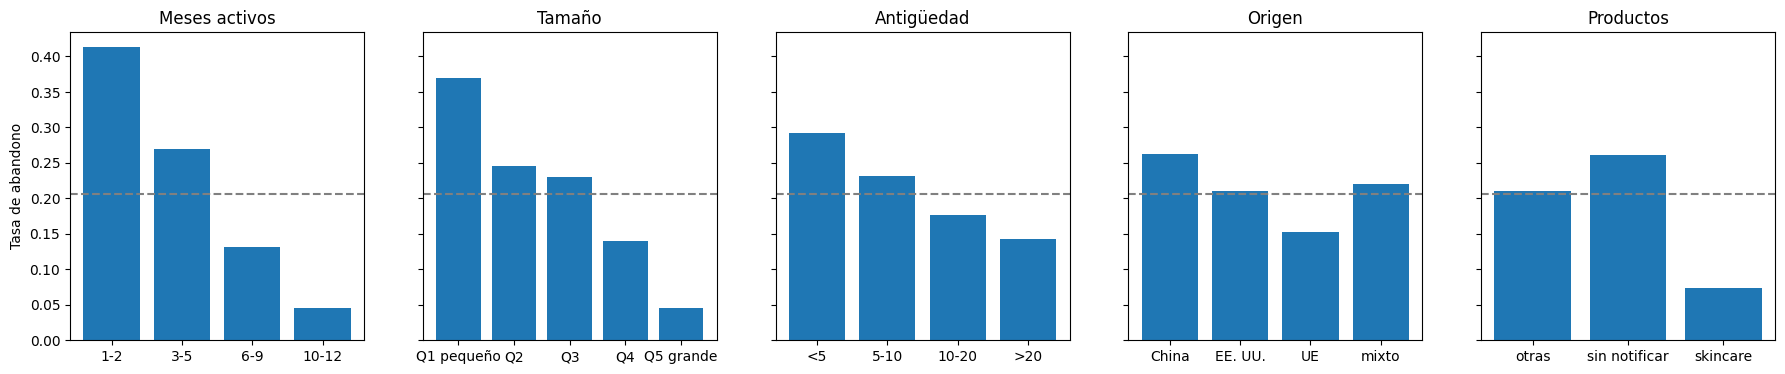

In [74]:
con_desenlace["Tamaño"] = pd.qcut(con_desenlace["cif_t"], 5, labels=["Q1 pequeño", "Q2", "Q3", "Q4", "Q5 grande"])
con_desenlace["Meses activos"] = pd.cut(con_desenlace["n_meses_activos_t"], [0, 2, 5, 9, 12], labels=["1-2", "3-5", "6-9", "10-12"])
con_desenlace["Antigüedad"] = pd.cut(con_desenlace["edad_anios_t"], [0, 5, 10, 20, 100], labels=["<5", "5-10", "10-20", ">20"])
con_desenlace["Origen"] = con_desenlace[["share_china_t", "share_ue_t", "share_usa_t"]].idxmax(axis=1)
con_desenlace.loc[con_desenlace[["share_china_t", "share_ue_t", "share_usa_t"]].max(axis=1) < 0.5, "Origen"] = "mixto"
con_desenlace["Origen"] = con_desenlace["Origen"].replace({"share_china_t": "China", "share_ue_t": "UE", "share_usa_t": "EE. UU."})
con_desenlace["Productos"] = np.where(con_desenlace["reg_t"] == 0, "sin notificar",
                              np.where(con_desenlace["cat_skincare"] > 0, "skincare", "otras"))

grupos = ["Meses activos", "Tamaño", "Antigüedad", "Origen", "Productos"]
fig, ejes = plt.subplots(1, 5, figsize=(22, 4), sharey=True)
for eje, grupo in zip(ejes, grupos):
    tasas = con_desenlace.groupby(grupo)[OBJETIVO].mean()
    eje.bar(tasas.index.astype(str), tasas.values)
    eje.axhline(con_desenlace[OBJETIVO].mean(), color="gray", linestyle="--")
    eje.set_title(grupo)
ejes[0].set_ylabel("Tasa de abandono")
plt.show()

- **Meses activos:** quien importa 1 o 2 meses al año abandona cerca de 10 veces más que quien importa 10 a 12 meses. Es la señal más fuerte.
- **Tamaño y antigüedad:** los importadores pequeños y las empresas jóvenes abandonan más.
- **Origen y tipo de producto:** las diferencias son menores.

### 7.3 Diagramas de caja: los que abandonan frente a los que se quedan

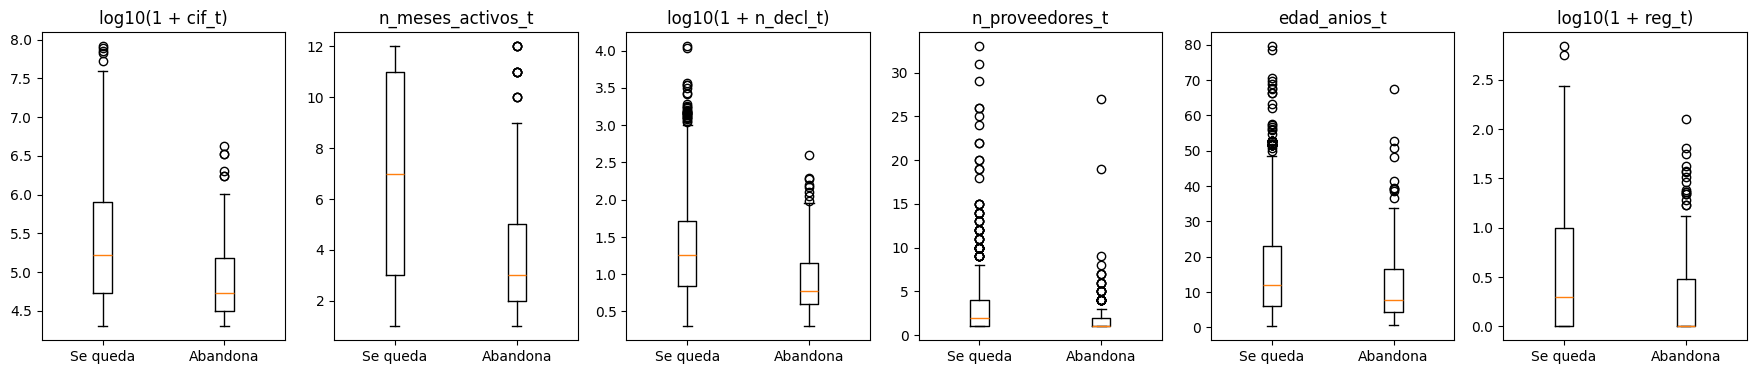

In [75]:
variables_caja = ["cif_t", "n_meses_activos_t", "n_decl_t", "n_proveedores_t", "edad_anios_t", "reg_t"]
fig, ejes = plt.subplots(1, 6, figsize=(22, 4))
for eje, col in zip(ejes, variables_caja):
    valores = con_desenlace[col]
    if col in ["cif_t", "n_decl_t", "reg_t"]:
        valores = np.log10(1 + valores)
        eje.set_title("log10(1 + " + col + ")")
    else:
        eje.set_title(col)
    se_queda = valores[con_desenlace[OBJETIVO] == 0].dropna()
    abandona = valores[con_desenlace[OBJETIVO] == 1].dropna()
    eje.boxplot([se_queda, abandona])
    eje.set_xticks([1, 2], ["Se queda", "Abandona"])
plt.show()

Los que abandonan importan menos, en menos meses y a menos proveedores, y son empresas más jóvenes. Las cajas se traslapan, así que ninguna variable sola basta.

### 7.4 Qué variables se mueven juntas (correlaciones)

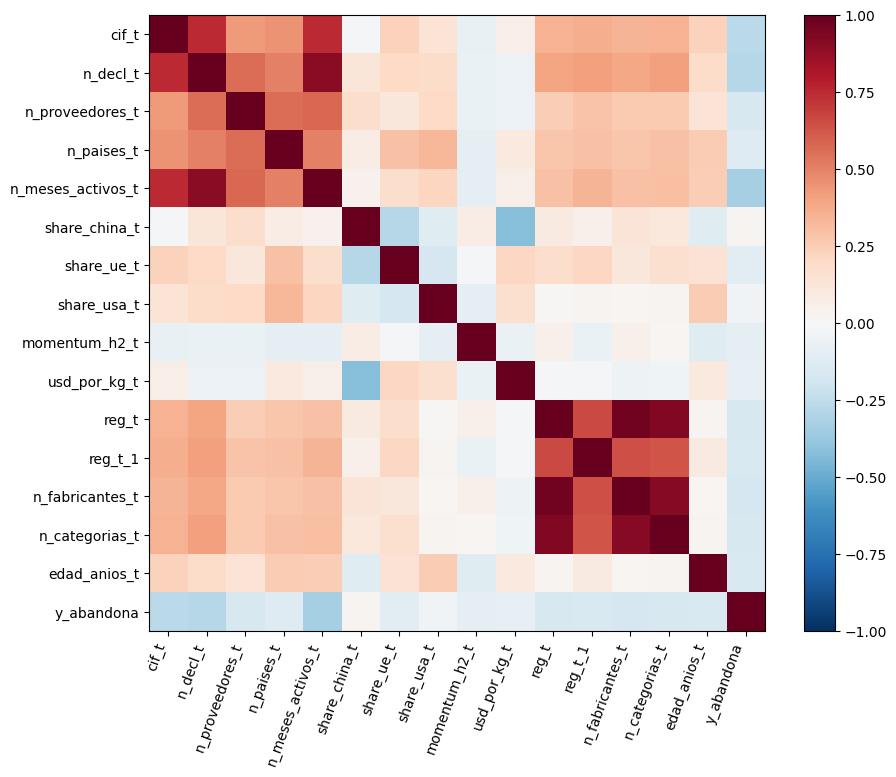

In [76]:
variables_corr = ["cif_t", "n_decl_t", "n_proveedores_t", "n_paises_t", "n_meses_activos_t", "share_china_t",
                  "share_ue_t", "share_usa_t", "momentum_h2_t", "usd_por_kg_t", "reg_t", "reg_t_1",
                  "n_fabricantes_t", "n_categorias_t", "edad_anios_t", OBJETIVO]
correlacion = con_desenlace[variables_corr].corr(method="spearman")

plt.figure(figsize=(10, 8))
plt.imshow(correlacion, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(variables_corr)), variables_corr, rotation=70, ha="right")
plt.yticks(range(len(variables_corr)), variables_corr)
plt.show()

Las variables de tamaño (CIF, declaraciones, meses, proveedores) se mueven juntas. En la regresión logística no metemos dos versiones de la misma variable (usamos el logaritmo del CIF y no el CIF).

## 8. Variables que construimos

| Variable | Cálculo | Idea de negocio |
|---|---|---|
| `log_cif` | log10(CIF) | Tamaño, sin que los gigantes dominen |
| `intensidad_sanitaria` | notificaciones nuevas / millón de US$ | ¿Invierte en ampliar portafolio o solo mueve volumen? |
| `log_valor_por_mes` | log10(CIF / meses activos) | Grande y constante frente a una sola compra grande |
| `decl_por_proveedor` | declaraciones / proveedores | Comprar seguido a los mismos proveedores = relación estable |
| `afinidad_seoru` | % de productos con palabras de la línea Seoru | Encaje con sérums, limpiadores y protector solar facial |
| `grupo_actividad` | CIIU 46, 47 u otro | Mayorista, minorista u otra actividad |

Ningún denominador es cero: todos tienen al menos 1 mes activo, 1 proveedor y CIF > 0. Si no hay productos notificados, la afinidad vale 0.

In [77]:
PALABRAS_SEORU = ["SERUM", "SÉRUM", "NIACINAMIDA", "NIACINAMIDE", "HIALURONICO", "HIALURÓNICO", "HYALURONIC",
                  "LIMPIADOR FACIAL", "GEL LIMPIADOR", "ESPUMA LIMPIADORA", "CLEANSER", "PROTECTOR SOLAR FACIAL",
                  "SOLAR FACIAL", "SUNSCREEN", "ESENCIA", "ESSENCE", "TONICO FACIAL", "TÓNICO FACIAL", "K-BEAUTY", "COREA"]

def afinidad(texto):
    if pd.isna(texto):
        return 0.0
    productos = [p.strip().upper() for p in str(texto).split("|") if p.strip()]
    if len(productos) == 0:
        return 0.0
    con_palabra = 0
    for producto in productos:
        if any(palabra in producto for palabra in PALABRAS_SEORU):
            con_palabra += 1
    return con_palabra / len(productos)

datos["log_cif"] = np.log10(datos["cif_t"])
datos["intensidad_sanitaria"] = datos["reg_t"] / (datos["cif_t"] / 1e6)
datos["log_valor_por_mes"] = np.log10(datos["cif_t"] / datos["n_meses_activos_t"])
datos["decl_por_proveedor"] = datos["n_decl_t"] / datos["n_proveedores_t"]
datos["afinidad_seoru"] = datos["texto_productos_t"].apply(afinidad)
ciiu_2_digitos = datos["ciiu_2"].fillna(0).astype(int).astype(str).str[:2]
datos["grupo_actividad"] = np.select([ciiu_2_digitos == "46", ciiu_2_digitos == "47"],
                                     ["comercio mayorista", "comercio minorista"], "otra actividad")
datos["forma"] = datos["forma"].fillna("DESCONOCIDA")

### 8.1 ¿Las variables nuevas ayudan a separar a los que abandonan?

In [78]:
entrenamiento_crudo = datos[datos["anio_t"] == ANIO_ENTRENAMIENTO]
nuevas = ["log_cif", "intensidad_sanitaria", "log_valor_por_mes", "decl_por_proveedor", "afinidad_seoru"]

filas = []
for col in nuevas:
    quintil = pd.qcut(entrenamiento_crudo[col].rank(method="first"), 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"])
    tasas = entrenamiento_crudo.groupby(quintil)[OBJETIVO].mean()
    auc = roc_auc_score(entrenamiento_crudo[OBJETIVO], entrenamiento_crudo[col])
    filas.append([col, auc] + tasas.tolist())

pd.DataFrame(filas, columns=["Variable", "AUC", "Q1 (bajo)", "Q2", "Q3", "Q4", "Q5 (alto)"]).round(3)

,Variable,AUC,Q1 (bajo),Q2,Q3,Q4,Q5 (alto)
0,log_cif,0.309,0.40,0.273,0.242,0.121,0.05
1,intensidad_sanitaria,0.462,0.18,0.333,0.192,0.141,0.24
2,log_valor_por_mes,0.397,0.27,0.242,0.333,0.131,0.11
3,decl_por_proveedor,0.321,0.37,0.263,0.232,0.162,0.06
4,afinidad_seoru,0.438,0.14,0.192,0.263,0.394,0.10


In [79]:
print(entrenamiento_crudo.groupby("grupo_actividad")[OBJETIVO].agg(["count", "mean"]).round(3))
print()
print(entrenamiento_crudo.groupby(entrenamiento_crudo["afinidad_seoru"] > 0)[OBJETIVO].agg(["count", "mean"]).round(3))

                    count   mean
grupo_actividad                 
comercio mayorista    296  0.226
comercio minorista    135  0.215
otra actividad         66  0.182

                count   mean
afinidad_seoru              
False             402  0.244
True               95  0.105


- **Declaraciones por proveedor** es la variable nueva que más separa: en el quintil más bajo abandona 37 % y en el más alto, 6 %.
- **Afinidad con Seoru:** quienes tienen productos de la línea de Seoru abandonan menos (10,5 % frente a 24,4 %). Además, sirve para ordenar a los candidatos.
- **Intensidad sanitaria y grupo de actividad** aportan poco.

## 9. Separar los datos: aprendemos con 2023 y probamos con 2024

Todo se elige con 2023: el corte de la regla, los parámetros, los umbrales y las medianas para completar nulos. 2024 solo se usa al final, una vez, para medir.

In [80]:
NUMERICAS = ["log_cif", "n_decl_t", "n_proveedores_t", "n_paises_t", "n_meses_activos_t", "share_china_t",
             "share_ue_t", "share_usa_t", "momentum_h2_t", "usd_por_kg_t", "reg_t", "reg_crec",
             "share_fab_extranjero_t", "n_fabricantes_t", "cat_skincare", "cat_maquillaje", "cat_capilar",
             "cat_corporal", "cat_solar", "n_categorias_t", "edad_anios_t", "camara_bogota",
             "intensidad_sanitaria", "log_valor_por_mes", "decl_por_proveedor", "afinidad_seoru"]
CATEGORICAS = ["forma", "grupo_actividad"]
CON_LOG = ["n_decl_t", "n_proveedores_t", "n_paises_t", "usd_por_kg_t", "reg_t", "n_fabricantes_t",
           "intensidad_sanitaria", "decl_por_proveedor"] # conteos muy sesgados: se usa log10(1 + x)

entrenamiento = datos[datos["anio_t"] == ANIO_ENTRENAMIENTO].reset_index(drop=True)
prueba = datos[datos["anio_t"] == ANIO_PRUEBA].reset_index(drop=True)
radar = datos[datos["anio_t"] == ANIO_RADAR].reset_index(drop=True)

X_ent_original = entrenamiento[NUMERICAS + CATEGORICAS]
X_pru_original = prueba[NUMERICAS + CATEGORICAS]
y_ent = entrenamiento[OBJETIVO].astype(int)
y_pru = prueba[OBJETIVO].astype(int)

print("Entrenamiento:", len(entrenamiento), "importadores, tasa de abandono", round(y_ent.mean(), 3))
print("Prueba:", len(prueba), "importadores, tasa de abandono", round(y_pru.mean(), 3))

Entrenamiento: 497 importadores, tasa de abandono 0.217
Prueba: 503 importadores, tasa de abandono 0.195


## 10. Cómo medimos: costo de los errores por cada 100 importadores

In [81]:
def costo_por_100(y_real, decision):
    y_real = np.asarray(y_real).astype(int)
    decision = np.asarray(decision).astype(int)
    return COSTO[decision, y_real].mean() * 100

def decidir(prob, umbral_1, umbral_2):
    # prob < umbral_1: firmar; entre los dos: firmar con garantías; prob >= umbral_2: no firmar
    prob = np.asarray(prob)
    return np.where(prob < umbral_1, FIRMAR, np.where(prob < umbral_2, GARANTIAS, NO_FIRMAR))

## 11. Punto de comparación: la regla simple de los meses activos

**Regla simple:** no firmar con quien importa en pocos meses del año. Probamos todos los cortes en 2023 y nos quedamos con el más barato. También dejamos la opción de una franja con garantías.

In [82]:
meses_ent = entrenamiento["n_meses_activos_t"].values
mejor_costo = None
for corte_1 in range(1, 13): # meses < corte_1: no firmar
    for corte_2 in range(corte_1, 14): # corte_1 <= meses < corte_2: garantías; meses >= corte_2: firmar
        decision = np.where(meses_ent < corte_1, NO_FIRMAR, np.where(meses_ent < corte_2, GARANTIAS, FIRMAR))
        costo = costo_por_100(y_ent, decision)
        if mejor_costo is None or costo < mejor_costo:
            mejor_costo, CORTE_1, CORTE_2 = costo, corte_1, corte_2

print("No firmar si meses activos <", CORTE_1)
print("Firmar con garantías si", CORTE_1, "<= meses activos <", CORTE_2)
print("Costo en 2023: US$", round(mejor_costo), "por cada 100")

No firmar si meses activos < 7
Firmar con garantías si 7 <= meses activos < 7
Costo en 2023: US$ 2575453 por cada 100


Los dos cortes quedaron iguales (7), así que la franja de garantías queda vacía. La regla es: **no firmar con quien importa en menos de 7 meses al año**.

In [83]:
def regla_simple(tabla):
    meses = tabla["n_meses_activos_t"].values
    return np.where(meses < CORTE_1, NO_FIRMAR, np.where(meses < CORTE_2, GARANTIAS, FIRMAR))

## 12. Limpiar y transformar los datos para los modelos

Todo se aprende con los datos de entrenamiento y después se aplica igual a los de prueba:
1. Completar nulos con la mediana.
2. Recortar los atípicos a los percentiles 1 y 99 (no se borran filas).
3. Pasar a log10(1 + x) los conteos muy sesgados.
4. Categóricas a columnas de 0 y 1.
5. Solo para la regresión logística: z-score de las numéricas.

In [84]:
def aprender_preparacion(X_tabla):
    numeros = X_tabla[NUMERICAS]
    medianas = numeros.median()
    numeros = numeros.fillna(medianas)
    p01 = numeros.quantile(0.01)
    p99 = numeros.quantile(0.99)
    numeros = numeros.clip(p01, p99, axis=1)
    numeros[CON_LOG] = np.log10(1 + numeros[CON_LOG].clip(lower=0))
    columnas_dummies = pd.get_dummies(X_tabla[CATEGORICAS], dtype=float).columns
    return {"medianas": medianas, "p01": p01, "p99": p99,
            "medias": numeros.mean(), "desviaciones": numeros.std(ddof=0),
            "columnas_dummies": columnas_dummies}

def aplicar_preparacion(X_tabla, prep, zscore):
    numeros = X_tabla[NUMERICAS].fillna(prep["medianas"])
    numeros = numeros.clip(prep["p01"], prep["p99"], axis=1)
    numeros[CON_LOG] = np.log10(1 + numeros[CON_LOG].clip(lower=0))
    if zscore:
        numeros = (numeros - prep["medias"]) / prep["desviaciones"]
    dummies = pd.get_dummies(X_tabla[CATEGORICAS], dtype=float).reindex(columns=prep["columnas_dummies"], fill_value=0)
    return pd.concat([numeros, dummies], axis=1)

## 13. Elegir el mejor modelo con validación cruzada (solo 2023)

Cada importador de 2023 recibe una probabilidad calculada por un modelo que no lo vio. Con esas probabilidades elegimos los parámetros y los umbrales.

In [85]:
batches = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEMILLA)

def probabilidades_cv(crear_modelo, zscore):
    probabilidades = np.zeros(len(y_ent))
    for ent, pru in batches.split(X_ent_original, y_ent):
        # aprender la preparación solo con el batch de entrenamiento
        prep = aprender_preparacion(X_ent_original.iloc[ent])
        X_b_ent = aplicar_preparacion(X_ent_original.iloc[ent], prep, zscore)
        X_b_pru = aplicar_preparacion(X_ent_original.iloc[pru], prep, zscore)
        # entrenar y predecir
        modelo = crear_modelo()
        modelo.fit(X_b_ent, y_ent.iloc[ent])
        probabilidades[pru] = modelo.predict_proba(X_b_pru)[:, 1]
    return probabilidades

### 13.1 Cuándo firmar, firmar con garantías o no firmar (umbrales)

In [86]:
UMBRALES = np.round(np.arange(0.02, 0.81, 0.01), 2)

def mejores_umbrales(y_real, prob):
    mejor = [np.inf, None, None]
    for i, umbral_1 in enumerate(UMBRALES):
        for umbral_2 in UMBRALES[i:]:
            costo = costo_por_100(y_real, decidir(prob, umbral_1, umbral_2))
            if costo < mejor[0]:
                mejor = [costo, umbral_1, umbral_2]
    return mejor

### 13.2 Probar varias versiones de la logística y del árbol

In [87]:
filas = []
probabilidades_guardadas = {}

for C in [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3]:
    crear = lambda C=C: LogisticRegression(C=C, max_iter=2000)
    prob = probabilidades_cv(crear, zscore=True)
    costo, u1, u2 = mejores_umbrales(y_ent, prob)
    nombre = "Logística C=" + str(C)
    filas.append(["Logística", nombre, costo, u1, u2, roc_auc_score(y_ent, prob)])
    probabilidades_guardadas[nombre] = prob

for profundidad in [2, 3, 4, 5, 6]:
    for hoja in [10, 20, 40]:
        crear = lambda p=profundidad, h=hoja: DecisionTreeClassifier(max_depth=p, min_samples_leaf=h, random_state=SEMILLA)
        prob = probabilidades_cv(crear, zscore=False)
        costo, u1, u2 = mejores_umbrales(y_ent, prob)
        nombre = "Árbol prof=" + str(profundidad) + " hoja=" + str(hoja)
        filas.append(["Árbol", nombre, costo, u1, u2, roc_auc_score(y_ent, prob)])
        probabilidades_guardadas[nombre] = prob

resultados_cv = pd.DataFrame(filas, columns=["Modelo", "Parámetros", "Costo CV por 100", "Umbral 1", "Umbral 2", "AUC CV"])
resultados_cv.sort_values("Costo CV por 100").groupby("Modelo").head(3).round(3)

,Modelo,Parámetros,Costo CV por 100,Umbral 1,Umbral 2,AUC CV
1,Logística,Logística C=0.003,2649899.396,0.17,0.24,0.737
2,Logística,Logística C=0.01,2657947.686,0.15,0.25,0.742
0,Logística,Logística C=0.001,2678068.410,0.20,0.23,0.731
18,Árbol,Árbol prof=5 hoja=20,2806841.046,0.02,0.18,0.707
8,Árbol,Árbol prof=2 hoja=10,2820925.553,0.06,0.09,0.662
9,Árbol,Árbol prof=2 hoja=20,2820925.553,0.06,0.09,0.659


In [88]:
mejor_logistica = resultados_cv[resultados_cv["Modelo"] == "Logística"].sort_values("Costo CV por 100").iloc[0]
mejor_arbol = resultados_cv[resultados_cv["Modelo"] == "Árbol"].sort_values("Costo CV por 100").iloc[0]
print(mejor_logistica["Parámetros"], "| umbrales", mejor_logistica["Umbral 1"], "y", mejor_logistica["Umbral 2"])
print(mejor_arbol["Parámetros"], "| umbrales", mejor_arbol["Umbral 1"], "y", mejor_arbol["Umbral 2"])

Logística C=0.003 | umbrales 0.17 y 0.24
Árbol prof=5 hoja=20 | umbrales 0.02 y 0.18


Escribimos aquí los parámetros que salieron:

In [89]:
C_ELEGIDO = 0.003
PROFUNDIDAD_ELEGIDA = 5
HOJA_ELEGIDA = 20
U1_LOG, U2_LOG = mejor_logistica["Umbral 1"], mejor_logistica["Umbral 2"]
U1_ARBOL, U2_ARBOL = mejor_arbol["Umbral 1"], mejor_arbol["Umbral 2"]

### **13.2 Random forest**

In [90]:

for arboles in [200, 400]:
    for profundidad in [None, 8]:
        for hoja in [10, 20]:

            crear = lambda n=arboles, p=profundidad, h=hoja: RandomForestClassifier(
                n_estimators=n,
                max_depth=p,
                min_samples_leaf=h,
                random_state=SEMILLA,
                n_jobs=-1,
                class_weight="balanced"
            )

            prob = probabilidades_cv(crear, zscore=False)

            costo, u1, u2 = mejores_umbrales(y_ent, prob)

            nombre = (
                "Random Forest árboles=" + str(arboles) +
                " profundidad=" + str(profundidad) +
                " hoja=" + str(hoja)
            )

            filas.append([
                "Random Forest", nombre, costo, u1, u2,
                roc_auc_score(y_ent, prob)
            ])

            probabilidades_guardadas[nombre] = prob


### **13.3 Gradient Boosting**

In [91]:

for arboles in [100, 200]:
    for tasa in [0.03, 0.1]:
        for profundidad in [1, 2]:

            crear = lambda n=arboles, lr=tasa, p=profundidad: GradientBoostingClassifier(
                n_estimators=n,
                learning_rate=lr,
                max_depth=p,
                random_state=SEMILLA
            )

            prob = probabilidades_cv(crear, zscore=False)

            costo, u1, u2 = mejores_umbrales(y_ent, prob)

            nombre = (
                "Gradient Boosting árboles=" + str(arboles) +
                " tasa=" + str(tasa) +
                " profundidad=" + str(profundidad)
            )

            filas.append([
                "Gradient Boosting", nombre, costo, u1, u2,
                roc_auc_score(y_ent, prob)
            ])

            probabilidades_guardadas[nombre] = prob


### **13.4 Tabla Comparativa actualizada**

In [92]:

resultados_cv = pd.DataFrame(
    filas,
    columns=[
        "Modelo",
        "Parámetros",
        "Costo CV por 100",
        "Umbral 1",
        "Umbral 2",
        "AUC CV"
    ]
)

resultados_cv.sort_values(
    "Costo CV por 100"
).groupby("Modelo").head(3).round(3)


,Modelo,Parámetros,Costo CV por 100,Umbral 1,Umbral 2,AUC CV
36,Gradient Boosting,Gradient Boosting árboles=200 tasa=0.03 profundidad=2,2507042.254,0.10,0.16,0.747
32,Gradient Boosting,Gradient Boosting árboles=100 tasa=0.03 profundidad=2,2515090.543,0.15,0.15,0.742
27,Random Forest,Random Forest árboles=400 profundidad=None hoja=10,2531187.123,0.33,0.40,0.745
31,Gradient Boosting,Gradient Boosting árboles=100 tasa=0.03 profundidad=1,2557344.064,0.14,0.21,0.745
29,Random Forest,Random Forest árboles=400 profundidad=8 hoja=10,2561368.209,0.33,0.39,0.744
23,Random Forest,Random Forest árboles=200 profundidad=None hoja=10,2561368.209,0.36,0.40,0.746
1,Logística,Logística C=0.003,2649899.396,0.17,0.24,0.737
2,Logística,Logística C=0.01,2657947.686,0.15,0.25,0.742
0,Logística,Logística C=0.001,2678068.410,0.20,0.23,0.731
18,Árbol,Árbol prof=5 hoja=20,2806841.046,0.02,0.18,0.707


### **13.5 Seleccionar la mejor configuración de cada modelo**

In [93]:

mejores_modelos = (
    resultados_cv
    .sort_values("Costo CV por 100")
    .groupby("Modelo")
    .first()
    .reset_index()
)

display(mejores_modelos)


,Modelo,Parámetros,Costo CV por 100,Umbral 1,Umbral 2,AUC CV
0,Gradient Boosting,Gradient Boosting árboles=200 tasa=0.03 profundidad=2,2.507042e+06,0.10,0.16,0.746596
1,Logística,Logística C=0.003,2.649899e+06,0.17,0.24,0.737289
2,Random Forest,Random Forest árboles=400 profundidad=None hoja=10,2.531187e+06,0.33,0.40,0.744882
3,Árbol,Árbol prof=5 hoja=20,2.806841e+06,0.02,0.18,0.706822


### **13.6 Mostrar los parámetros completos de los mejores modelos**

In [94]:
pd.set_option("display.max_colwidth", None)

mejores_modelos[
    ["Modelo", "Parámetros", "Costo CV por 100", "Umbral 1", "Umbral 2"]
]


,Modelo,Parámetros,Costo CV por 100,Umbral 1,Umbral 2
0,Gradient Boosting,Gradient Boosting árboles=200 tasa=0.03 profundidad=2,2.507042e+06,0.10,0.16
1,Logística,Logística C=0.003,2.649899e+06,0.17,0.24
2,Random Forest,Random Forest árboles=400 profundidad=None hoja=10,2.531187e+06,0.33,0.40
3,Árbol,Árbol prof=5 hoja=20,2.806841e+06,0.02,0.18


### **13.7 Selección final del modelo**

In [95]:


# Seleccionar el modelo con menor costo en validación cruzada (2023)
mejor_fila = mejores_modelos.loc[
    mejores_modelos["Costo CV por 100"].idxmin()
]

MODELO_FINAL = mejor_fila["Modelo"]
UMBRAL_1_FINAL = mejor_fila["Umbral 1"]
UMBRAL_2_FINAL = mejor_fila["Umbral 2"]

print("MODELO SELECCIONADO:", MODELO_FINAL)
print("Costo CV por cada 100 importadores: US$",
      round(mejor_fila["Costo CV por 100"]))
print("AUC en validación cruzada:",
      round(mejor_fila["AUC CV"], 3))
print("Umbral 1:", UMBRAL_1_FINAL)
print("Umbral 2:", UMBRAL_2_FINAL)

print("\nCriterio de selección:")
print("Se selecciona el modelo con menor costo promedio")
print("en validación cruzada utilizando únicamente datos de 2023.")


MODELO SELECCIONADO: Gradient Boosting
Costo CV por cada 100 importadores: US$ 2507042
AUC en validación cruzada: 0.747
Umbral 1: 0.1
Umbral 2: 0.16

Criterio de selección:
Se selecciona el modelo con menor costo promedio
en validación cruzada utilizando únicamente datos de 2023.


Se seleccionó Gradient Boosting por presentar el menor costo promedio en la validación cruzada de 2023 (US$2.507.042 por cada 100 importadores). Esta elección prioriza el impacto económico de las decisiones comerciales y evita seleccionar el modelo utilizando los resultados del conjunto de prueba de 2024.

## **14. Entrenar los modelos elegidos**

In [96]:
prep_final = aprender_preparacion(X_ent_original)

X_ent_log = aplicar_preparacion(X_ent_original, prep_final, zscore=True)
X_pru_log = aplicar_preparacion(X_pru_original, prep_final, zscore=True)
logistica = LogisticRegression(C=C_ELEGIDO, max_iter=2000)
logistica.fit(X_ent_log, y_ent)

X_ent_arbol = aplicar_preparacion(X_ent_original, prep_final, zscore=False)
X_pru_arbol = aplicar_preparacion(X_pru_original, prep_final, zscore=False)
arbol = DecisionTreeClassifier(max_depth=PROFUNDIDAD_ELEGIDA, min_samples_leaf=HOJA_ELEGIDA, random_state=SEMILLA)
arbol.fit(X_ent_arbol, y_ent)

DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=42)

### **14.1 Entrenar Random forest y Gradient Boosting**

In [97]:
# 1. RANDOM FOREST
random_forest = RandomForestClassifier(
    n_estimators=400,
    max_depth=None,
    min_samples_leaf=10,
    random_state=SEMILLA,
    n_jobs=-1,
    class_weight="balanced"
)

random_forest.fit(X_ent_arbol, y_ent)


# 2. GRADIENT BOOSTING
gradient_boosting = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.03,
    max_depth=2,
    random_state=SEMILLA
)

gradient_boosting.fit(X_ent_arbol, y_ent)


print("Los cuatro modelos están entrenados:")
print("- Regresión logística")
print("- Árbol de decisión")
print("- Random Forest")
print("- Gradient Boosting")


Los cuatro modelos están entrenados:
- Regresión logística
- Árbol de decisión
- Random Forest
- Gradient Boosting


### 14.2 Qué variables suben o bajan el riesgo (regresión logística)

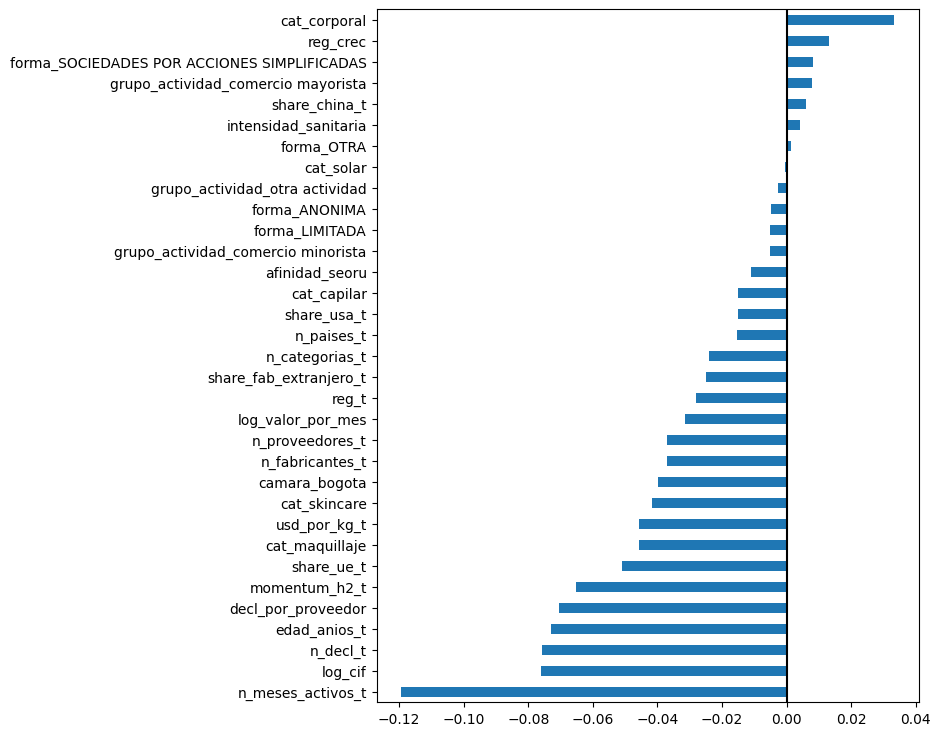

In [98]:
coeficientes = pd.Series(logistica.coef_[0], index=X_ent_log.columns).sort_values()
coeficientes.plot.barh(figsize=(7, 9))
plt.axvline(0, color="black")
plt.show()

Las variables que más bajan el riesgo son los meses activos, el tamaño, el número de declaraciones y la antigüedad.

### 14.3 Cómo decide el árbol de decisión

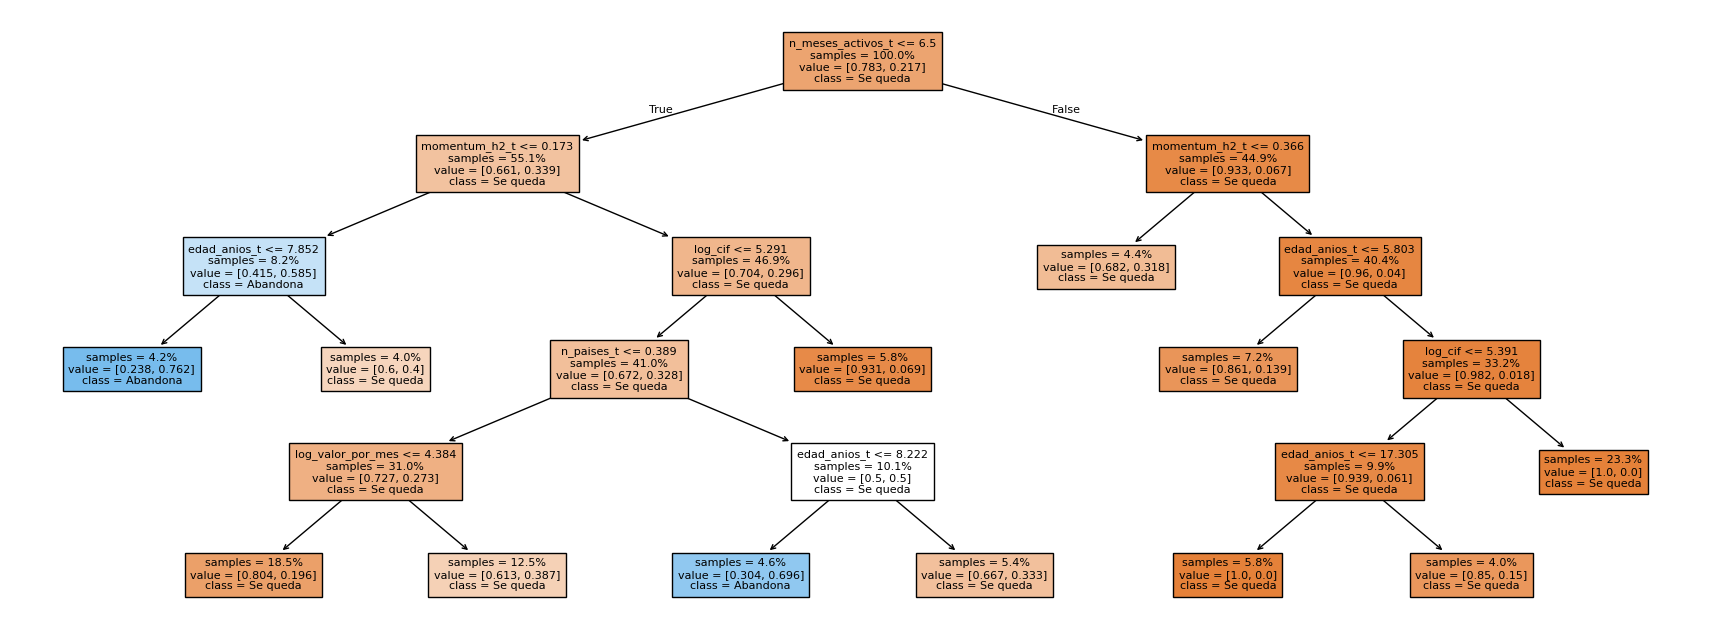

In [99]:
plt.figure(figsize=(22, 8))
plot_tree(arbol, feature_names=X_ent_arbol.columns, class_names=["Se queda", "Abandona"],
          filled=True, proportion=True, impurity=False, fontsize=8)
plt.show()

## **14.4 Predicciones en los datos de prueba 2024**

In [100]:

prob_logistica_2024 = logistica.predict_proba(X_pru_log)[:, 1]

prob_arbol_2024 = arbol.predict_proba(X_pru_arbol)[:, 1]

prob_rf_2024 = random_forest.predict_proba(X_pru_arbol)[:, 1]

prob_gb_2024 = gradient_boosting.predict_proba(X_pru_arbol)[:, 1]


print("Probabilidades calculadas para los cuatro modelos.")
print("Número de importadores evaluados:", len(y_pru))


Probabilidades calculadas para los cuatro modelos.
Número de importadores evaluados: 503


## 15. Resultados en 2024: ¿el modelo le gana a la regla?

In [101]:
prob_log = logistica.predict_proba(X_pru_log)[:, 1]
prob_arbol = arbol.predict_proba(X_pru_arbol)[:, 1]
prob_rf = random_forest.predict_proba(X_pru_arbol)[:, 1]
prob_gb = gradient_boosting.predict_proba(X_pru_arbol)[:, 1]
decisiones = {
    "Firmar con todos": np.full(len(y_pru), FIRMAR),
    "Garantías a todos": np.full(len(y_pru), GARANTIAS),
    "No firmar con nadie": np.full(len(y_pru), NO_FIRMAR),
    "Regla simple": regla_simple(prueba),
    "Regresión logística": decidir(prob_log, U1_LOG, U2_LOG),
    "Árbol de decisión": decidir(prob_arbol, U1_ARBOL, U2_ARBOL),
    "Random Forest": decidir(prob_rf, 0.33, 0.40),
    "Gradient Boosting": decidir(prob_gb, 0.10, 0.16),
}
puntajes = {"Regla simple": -prueba["n_meses_activos_t"], "Regresión logística": prob_log, "Árbol de decisión": prob_arbol, "Random Forest": prob_rf,
"Gradient Boosting": prob_gb}

### 15.1 Margen de error de los costos (bootstrap)

Sacamos 1.000 muestras con reemplazo de los importadores de prueba. Usamos las mismas muestras para todas las estrategias.

In [102]:
generador = np.random.default_rng(SEMILLA)
muestras = generador.integers(0, len(y_pru), size=(N_BOOTSTRAP, len(y_pru)))
y_pru_array = y_pru.values

def costos_bootstrap(decision):
    costos = []
    for muestra in muestras:
        costos.append(costo_por_100(y_pru_array[muestra], decision[muestra]))
    return np.array(costos)

### 15.2 Comparación de todas las estrategias

In [103]:
filas = []
for nombre, decision in decisiones.items():
    marcados = decision != FIRMAR # garantías o no firmar
    VP = (marcados & (y_pru_array == 1)).sum()
    bootstrap = costos_bootstrap(decision)
    filas.append({
        "Estrategia": nombre,
        "Costo por 100": costo_por_100(y_pru_array, decision),
        "IC 2,5 %": np.percentile(bootstrap, 2.5),
        "IC 97,5 %": np.percentile(bootstrap, 97.5),
        "Sensibilidad": VP / (y_pru_array == 1).sum(),
        "Precisión": VP / marcados.sum() if marcados.sum() > 0 else np.nan,
        "AUC": roc_auc_score(y_pru_array, puntajes[nombre]) if nombre in puntajes else np.nan,
        "% firmar": (decision == FIRMAR).mean(),
        "% garantías": (decision == GARANTIAS).mean(),
        "% no firmar": (decision == NO_FIRMAR).mean(),
    })
comparacion = pd.DataFrame(filas).set_index("Estrategia")
comparacion.round(3)

,Costo por 100,"IC 2,5 %","IC 97,5 %",Sensibilidad,Precisión,AUC,% firmar,% garantías,% no firmar
Estrategia,,,,,,,,,
Firmar con todos,4870775.348,4025844.930,5765407.555,0.000,NaN,NaN,1.000,0.000,0.000
Garantías a todos,3948310.139,3610337.972,4306163.022,1.000,0.195,NaN,0.000,1.000,0.000
No firmar con nadie,4025844.930,3846918.489,4194831.014,1.000,0.195,NaN,0.000,0.000,1.000
Regla simple,2793240.557,2375745.527,3230864.811,0.827,0.292,0.735,0.449,0.000,0.551
Regresión logística,2721669.980,2421471.173,3053727.634,0.949,0.258,0.740,0.282,0.302,0.416
Árbol de decisión,2912524.851,2552534.791,3250596.421,0.918,0.251,0.711,0.288,0.209,0.503
Random Forest,2681908.549,2238369.781,3087524.851,0.837,0.297,0.741,0.451,0.074,0.475
Gradient Boosting,2862823.062,2453230.616,3264413.519,0.837,0.264,0.745,0.382,0.139,0.479


- Sensibilidad: de los que abandonan, cuántos quedan marcados como riesgo (garantías o no firmar).
- Precisión: de los marcados como riesgo, cuántos abandonan de verdad.

### 15.3 ¿La diferencia entre el modelo y la regla es real?

In [104]:
bootstrap_regla = costos_bootstrap(decisiones["Regla simple"])
for nombre in [
    "Regresión logística",
    "Árbol de decisión",
    "Random Forest",
    "Gradient Boosting"
]:
    diferencia = costos_bootstrap(decisiones[nombre]) - bootstrap_regla
    observada = comparacion.loc[nombre, "Costo por 100"] - comparacion.loc["Regla simple", "Costo por 100"]
    print(nombre)
    print("  Diferencia (modelo - regla): US$", round(observada))
    print("  IC 95 %: US$", round(np.percentile(diferencia, 2.5)), "a US$", round(np.percentile(diferencia, 97.5)))
    print("  El modelo es más barato en el", round((diferencia < 0).mean() * 100), "% de las muestras")

Regresión logística
  Diferencia (modelo - regla): US$ -71571
  IC 95 %: US$ -375795 a US$ 200795
  El modelo es más barato en el 69 % de las muestras
Árbol de decisión
  Diferencia (modelo - regla): US$ 119284
  IC 95 %: US$ -147266 a US$ 359841
  El modelo es más barato en el 19 % de las muestras
Random Forest
  Diferencia (modelo - regla): US$ -111332
  IC 95 %: US$ -369831 a US$ 155119
  El modelo es más barato en el 79 % de las muestras
Gradient Boosting
  Diferencia (modelo - regla): US$ 69583
  IC 95 %: US$ -220775 a US$ 339960
  El modelo es más barato en el 33 % de las muestras


**Conclusión:**
Random Forest obtuvo el menor costo observado, con US$2,68 millones por cada 100 importadores, frente a US 2,79 millones de la regla simple. Sin embargo, su intervalo de confianza incluye el cero, por lo que no podemos afirmar que el ahorro sea estadísticamente significativo.

Gradient Boosting alcanzó el mayor AUC (0,745), mientras que la regresión logística presentó la mayor sensibilidad (94,9 %). Por tanto, Gradient Boosting fue seleccionado como modelo final por presentar el menor costo promedio en validación cruzada con los datos de 2023. Aunque Random Forest obtuvo el menor costo observado en la prueba de 2024 y Gradient Boosting alcanzó un AUC ligeramente superior, la selección se basó en el desempeño promedio de validación cruzada, sin utilizar los datos de prueba para elegir el modelo.

### 15.4 Aciertos y errores del modelo, en dólares

In [105]:
# Usar las decisiones del modelo seleccionado
decision = decisiones["Gradient Boosting"]

real = pd.Series(y_pru_array).replace({
    0: "Se queda",
    1: "Abandona"
})

predicho = pd.Series(decision).replace(NOMBRES)

# Tabla de aciertos y errores
conteos = pd.crosstab(
    real,
    predicho,
    rownames=["Real"],
    colnames=["Decisión"]
).reindex(
    index=["Se queda", "Abandona"],
    columns=list(NOMBRES.values()),
    fill_value=0
)

display(conteos)

# Calcular costos en dólares
dolares = conteos.copy().astype(float)

for numero, nombre in NOMBRES.items():
    dolares.loc["Se queda", nombre] = (
        conteos.loc["Se queda", nombre] * COSTO[numero, 0]
    )
    dolares.loc["Abandona", nombre] = (
        conteos.loc["Abandona", nombre] * COSTO[numero, 1]
    )

display(dolares)

total = dolares.values.sum()

print("Total: US$", round(total))
print(
    "Costo por cada 100 importadores: US$",
    round(total / len(y_pru) * 100)
)

Decisión,Firmar,Firmar con garantías,No firmar
Real,,,
Se queda,176,63,166
Abandona,16,7,75


Decisión,Firmar,Firmar con garantías,No firmar
Real,,,
Se queda,0.0,1260000.0,8300000.0
Abandona,4000000.0,840000.0,0.0


Total: US$ 14400000
Costo por cada 100 importadores: US$ 2862823


### 15.5 Cómo cambia el costo según el umbral

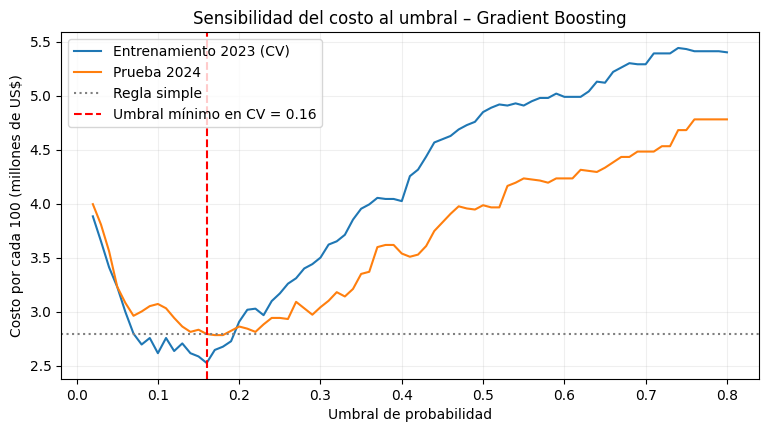

Umbral de menor costo en CV: 0.16
Costo mínimo CV: US$ 2525151


In [106]:


CLAVE_GB = "Gradient Boosting árboles=200 tasa=0.03 profundidad=2"

# Probabilidades de validación cruzada 2023
prob_cv_gb = probabilidades_guardadas[CLAVE_GB]

# Evaluar distintos umbrales usando el mismo valor para ambas decisiones
costo_cv = [
    costo_por_100(y_ent, decidir(prob_cv_gb, u, u))
    for u in UMBRALES
]

costo_prueba = [
    costo_por_100(y_pru_array, decidir(prob_gb_2024, u, u))
    for u in UMBRALES
]

# Umbral de menor costo en validación cruzada
umbral_unico = UMBRALES[np.argmin(costo_cv)]

plt.figure(figsize=(9, 4.5))

plt.plot(
    UMBRALES,
    np.array(costo_cv) / 1e6,
    label="Entrenamiento 2023 (CV)"
)

plt.plot(
    UMBRALES,
    np.array(costo_prueba) / 1e6,
    label="Prueba 2024"
)

plt.axhline(
    comparacion.loc["Regla simple", "Costo por 100"] / 1e6,
    color="gray",
    linestyle=":",
    label="Regla simple"
)

plt.axvline(
    umbral_unico,
    color="red",
    linestyle="--",
    label=f"Umbral mínimo en CV = {umbral_unico:.2f}"
)

plt.xlabel("Umbral de probabilidad")
plt.ylabel("Costo por cada 100 (millones de US$)")
plt.title("Sensibilidad del costo al umbral – Gradient Boosting")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print("Umbral de menor costo en CV:", umbral_unico)
print("Costo mínimo CV: US$", round(min(costo_cv)))


## 16. Índice de arraigo importador: el riesgo en un solo número

**Propuesta del equipo:** La afinidad no se utiliza para predecir el abandono, sino para ordenar candidatos según su encaje comercial con Seoru. Comparamos dos listas de 20 importadores en 2024: (A) los 20 con mayor índice de arraigo (IAI) y (B) entre aquellos para quienes Gradient Boosting recomienda firmar, con o sin garantías (IAI ≥ 84), los 20 con mayor afinidad con Seoru.

In [107]:
# Umbrales del modelo final Gradient Boosting
U1_GB = 0.10
U2_GB = 0.16

candidatos = prueba[
    ["nit", "razon_social", "afinidad_seoru", OBJETIVO]
].copy()

# Índice de arraigo importador
candidatos["IAI"] = 100 * (1 - prob_gb_2024)

# Lista A: 20 importadores con mayor IAI
lista_a = candidatos.sort_values(
    "IAI", ascending=False
).head(20)

# Lista B: importadores elegibles para firmar,
# con o sin garantías, priorizando la afinidad con Seoru
lista_b = candidatos[
    candidatos["IAI"] >= 100 * (1 - U2_GB)
].sort_values(
    ["afinidad_seoru", "IAI"],
    ascending=False
).head(20)

# Comparación de las dos listas
comparacion_listas = pd.DataFrame({
    "Lista A: mayor IAI": [
        lista_a["IAI"].mean(),
        lista_a["afinidad_seoru"].mean(),
        (lista_a["afinidad_seoru"] > 0).sum(),
        lista_a[OBJETIVO].mean()
    ],
    "Lista B: firmar + mayor afinidad": [
        lista_b["IAI"].mean(),
        lista_b["afinidad_seoru"].mean(),
        (lista_b["afinidad_seoru"] > 0).sum(),
        lista_b[OBJETIVO].mean()
    ]
}, index=[
    "IAI promedio",
    "Afinidad promedio",
    "Con afinidad > 0",
    "Abandono real"
])

display(comparacion_listas.round(3))

,Lista A: mayor IAI,Lista B: firmar + mayor afinidad
IAI promedio,97.688,95.318
Afinidad promedio,0.199,0.391
Con afinidad > 0,20.000,20.000
Abandono real,0.000,0.050


### 16.1 ¿Cómo cambia la lista de candidatos si priorizamos la afinidad con Seoru?

Para evaluar cómo influye la afinidad comercial en la selección de candidatos, comparamos dos listas de 20 importadores en 2024. La primera (A) incluye los 20 importadores con mayor índice de arraigo (IAI). La segunda (B) selecciona, entre los importadores con IAI igual o superior a 84 —es decir, aquellos con quienes se puede firmar, con o sin garantías—, los 20 que presentan mayor afinidad con Seoru. Así, evaluamos cómo cambia la selección cuando priorizamos el encaje comercial sin dejar de considerar el riesgo de abandono.

In [108]:
# Comparación de candidatos usando Gradient Boosting

candidatos = prueba[
    ["nit", "razon_social", "afinidad_seoru", OBJETIVO]
].copy()

# Índice de arraigo con el modelo final
candidatos["IAI"] = 100 * (1 - prob_gb_2024)

# Lista A: 20 importadores con mayor arraigo
lista_a = candidatos.sort_values(
    "IAI", ascending=False
).head(20)

# Lista B: entre quienes pueden firmar,
# seleccionar los 20 con mayor afinidad con Seoru
lista_b = candidatos[
    candidatos["IAI"] >= 84
].sort_values(
    ["afinidad_seoru", "IAI"],
    ascending=False
).head(20)

# Comparar las listas
comparacion_listas_161 = pd.DataFrame({
    "Lista A: mayor IAI": [
        lista_a["IAI"].mean(),
        lista_a["afinidad_seoru"].mean(),
        (lista_a["afinidad_seoru"] > 0).sum(),
        lista_a[OBJETIVO].mean()
    ],
    "Lista B: mayor afinidad": [
        lista_b["IAI"].mean(),
        lista_b["afinidad_seoru"].mean(),
        (lista_b["afinidad_seoru"] > 0).sum(),
        lista_b[OBJETIVO].mean()
    ]
}, index=[
    "IAI promedio",
    "Afinidad promedio",
    "Importadores con afinidad > 0",
    "Abandono real"
])

display(comparacion_listas_161.round(3))

print(
    "Importadores presentes en ambas listas:",
    len(set(lista_a["nit"]) & set(lista_b["nit"])),
    "de 20"
)

,Lista A: mayor IAI,Lista B: mayor afinidad
IAI promedio,97.688,95.318
Afinidad promedio,0.199,0.391
Importadores con afinidad > 0,20.000,20.000
Abandono real,0.000,0.050


Importadores presentes en ambas listas: 7 de 20


### **16.2 Segmentación de importadores mediante K-means.**

Variables utilizadas: ['n_meses_activos_t', 'n_decl_t', 'log_cif', 'decl_por_proveedor', 'edad_anios_t', 'momentum_h2_t', 'usd_por_kg_t', 'n_fabricantes_t', 'n_proveedores_t', 'log_valor_por_mes', 'afinidad_seoru']


,Clusters,Silhouette
0,2,0.346
1,3,0.273
2,4,0.199
3,5,0.168
4,6,0.187


Número de clusters elegido: 2
Perfil de los segmentos:


,importadores,tasa_abandono,n_meses_activos_t,n_decl_t,log_cif,decl_por_proveedor,edad_anios_t,momentum_h2_t,usd_por_kg_t,n_fabricantes_t,n_proveedores_t,log_valor_por_mes,afinidad_seoru
Cluster,,,,,,,,,,,,,
0,374,24.06,4.72,14.93,4.95,7.91,13.91,0.55,99.31,1.10,2.02,4.37,0.01
1,129,6.20,11.01,437.57,6.36,104.74,21.51,0.52,60.87,8.96,5.55,5.33,0.08


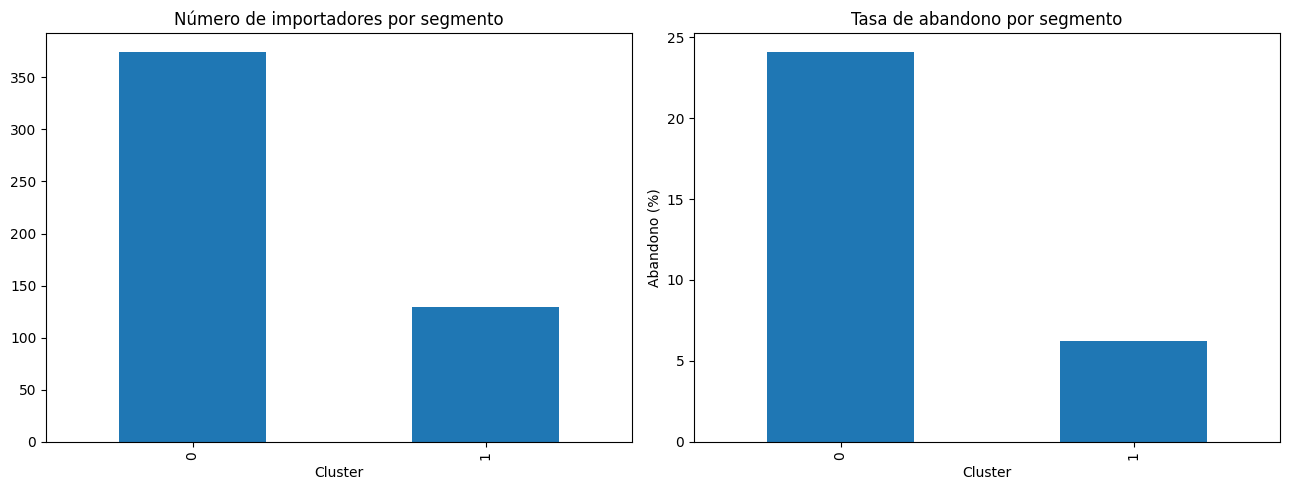

In [109]:
# 1. Seleccionar variables para la segmentación
variables_cluster = [
    "n_meses_activos_t",
    "n_decl_t",
    "log_cif",
    "decl_por_proveedor",
    "edad_anios_t",
    "momentum_h2_t",
    "usd_por_kg_t",
    "n_fabricantes_t",
    "n_proveedores_t",
    "log_valor_por_mes",
    "afinidad_seoru"
]

# Verificar cuáles variables están disponibles
variables_cluster = [
    v for v in variables_cluster if v in prueba.columns
]

print("Variables utilizadas:", variables_cluster)

# 2. Preparar los datos
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

X_cluster = prueba[variables_cluster].copy()

# Convertir variables a formato numérico
X_cluster = X_cluster.apply(pd.to_numeric, errors="coerce")

# Imputar valores faltantes
imputador_cluster = SimpleImputer(strategy="median")
X_imputado = imputador_cluster.fit_transform(X_cluster)

# Estandarizar variables
escalador_cluster = StandardScaler()
X_escalado = escalador_cluster.fit_transform(X_imputado)

# 3. Comparar diferentes números de clusters
resultados_silhouette = []

for k in range(2, 7):
    modelo_kmeans = KMeans(
        n_clusters=k,
        random_state=SEMILLA,
        n_init=20
    )

    etiquetas = modelo_kmeans.fit_predict(X_escalado)

    resultados_silhouette.append({
        "Clusters": k,
        "Silhouette": silhouette_score(X_escalado, etiquetas)
    })

tabla_silhouette = pd.DataFrame(resultados_silhouette)
display(tabla_silhouette.round(3))

# 4. Seleccionar el número de clusters con mayor Silhouette
K_ELEGIDO = int(
    tabla_silhouette.loc[
        tabla_silhouette["Silhouette"].idxmax(),
        "Clusters"
    ]
)

print("Número de clusters elegido:", K_ELEGIDO)

# 5. Entrenar el modelo final
kmeans_final = KMeans(
    n_clusters=K_ELEGIDO,
    random_state=SEMILLA,
    n_init=20
)

prueba_cluster = prueba.copy()
prueba_cluster["Cluster"] = kmeans_final.fit_predict(X_escalado)

# 6. Incorporar el abandono real para evaluar los grupos
prueba_cluster["Abandono_real"] = np.asarray(y_pru_array)

# 7. Perfil de cada cluster
perfil_clusters = prueba_cluster.groupby("Cluster").agg(
    importadores=("Cluster", "size"),
    tasa_abandono=("Abandono_real", "mean"),
    **{
        variable: (variable, "mean")
        for variable in variables_cluster
    }
)

perfil_clusters["tasa_abandono"] *= 100

print("Perfil de los segmentos:")
display(perfil_clusters.round(2))

# 8. Visualizar tamaño y tasa de abandono
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

perfil_clusters["importadores"].plot(
    kind="bar",
    ax=axes[0],
    title="Número de importadores por segmento"
)

perfil_clusters["tasa_abandono"].plot(
    kind="bar",
    ax=axes[1],
    title="Tasa de abandono por segmento",
    ylabel="Abandono (%)"
)

axes[0].set_xlabel("Cluster")
axes[1].set_xlabel("Cluster")

plt.tight_layout()
plt.show()

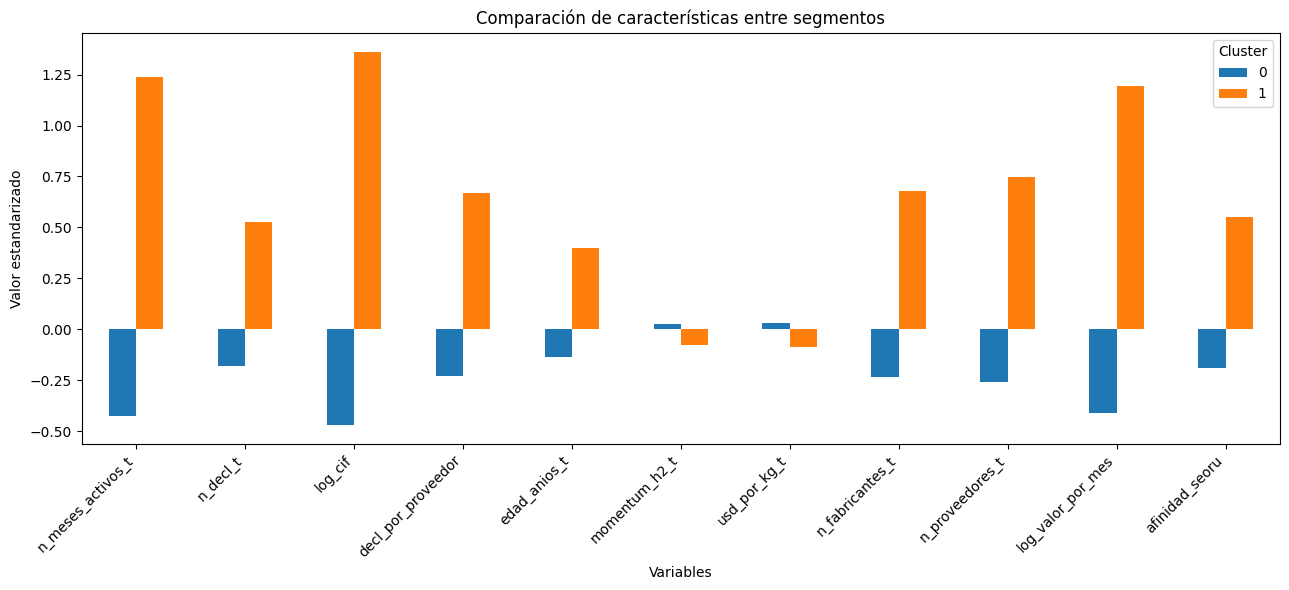

In [110]:
# Comparación de perfiles de los clusters
variables_comparacion = [
    "n_meses_activos_t",
    "n_decl_t",
    "log_cif",
    "decl_por_proveedor",
    "edad_anios_t",
    "n_fabricantes_t",
    "n_proveedores_t",
    "afinidad_seoru"
]

# Calcular promedios estandarizados para facilitar la comparación
perfil_estandarizado = pd.DataFrame(
    escalador_cluster.transform(
        imputador_cluster.transform(
            prueba_cluster[variables_cluster]
            .apply(pd.to_numeric, errors="coerce")
        )
    ),
    columns=variables_cluster,
    index=prueba_cluster.index
)

perfil_estandarizado["Cluster"] = prueba_cluster["Cluster"].values

perfil_comparado = perfil_estandarizado.groupby("Cluster").mean()

perfil_comparado.T.plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Comparación de características entre segmentos")
plt.ylabel("Valor estandarizado")
plt.xlabel("Variables")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

**Interpretación de los segmentos:** La segmentación identifica dos perfiles diferenciados. El Cluster 0 agrupa importadores con menor actividad comercial, menor volumen de importaciones y una tasa de abandono del 24,06%. Por su parte, el Cluster 1 reúne importadores más consolidados, con mayor actividad, diversidad de proveedores y fabricantes, y una tasa de abandono del 6,20%. Estos resultados sugieren que Seoru podría priorizar el acercamiento comercial al segundo segmento y desarrollar estrategias de seguimiento y fidelización para el primero.

# **18. ¿Qué variables explican las predicciones?**

### **18.1 — Importancia por permutación**

,Variable,Importancia,Desviacion
4,n_meses_activos_t,0.065346,0.014814
8,momentum_h2_t,0.053410,0.014735
15,cat_maquillaje,0.016194,0.005821
14,cat_skincare,0.005277,0.002776
5,share_china_t,0.003492,0.002835
22,intensidad_sanitaria,0.003334,0.002850
11,reg_crec,0.003060,0.001915
9,usd_por_kg_t,0.002858,0.002023
23,log_valor_por_mes,0.002307,0.002559
0,log_cif,0.002054,0.005913


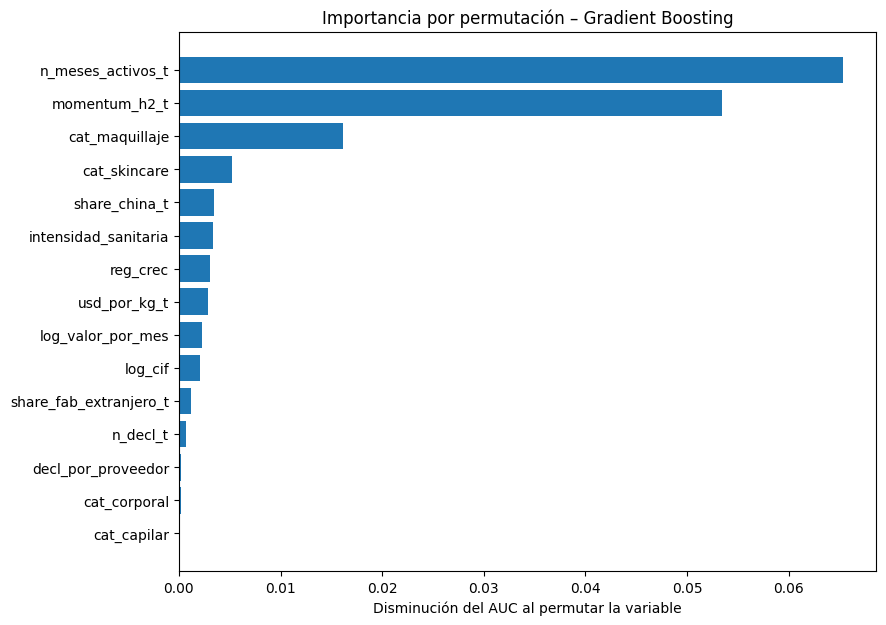

In [111]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Calcular importancia por permutación del modelo final
importancia = permutation_importance(
    gradient_boosting,
    X_pru_arbol,
    y_pru,
    n_repeats=30,
    random_state=42,
    scoring="roc_auc"
)

# Organizar resultados
tabla_importancia = pd.DataFrame({
    "Variable": X_pru_arbol.columns,
    "Importancia": importancia.importances_mean,
    "Desviacion": importancia.importances_std
}).sort_values("Importancia", ascending=False)

display(tabla_importancia)

# Graficar las 15 variables más importantes
top_importancia = tabla_importancia.head(15).sort_values("Importancia")

plt.figure(figsize=(9, 7))
plt.barh(top_importancia["Variable"], top_importancia["Importancia"])
plt.xlabel("Disminución del AUC al permutar la variable")
plt.title("Importancia por permutación – Gradient Boosting")
plt.show()

La importancia por permutación muestra que el modelo Gradient Boosting se apoya principalmente en el número de meses activos (n_meses_activos_t) y el comportamiento reciente de las importaciones (momentum_h2_t). Ambas variables presentan las mayores disminuciones del AUC cuando sus valores se permutan, lo que evidencia su relevancia para la capacidad predictiva del modelo. En tercer lugar aparece la categoría de maquillaje (cat_maquillaje), aunque con una contribución menor. Las demás variables presentan importancias relativamente reducidas. Estos resultados sugieren que la constancia y la evolución reciente de las importaciones son factores especialmente útiles para anticipar el abandono de los importadores.

### **18.2: Interpretación de las predicciones mediante SHAP**

In [112]:
!pip install shap

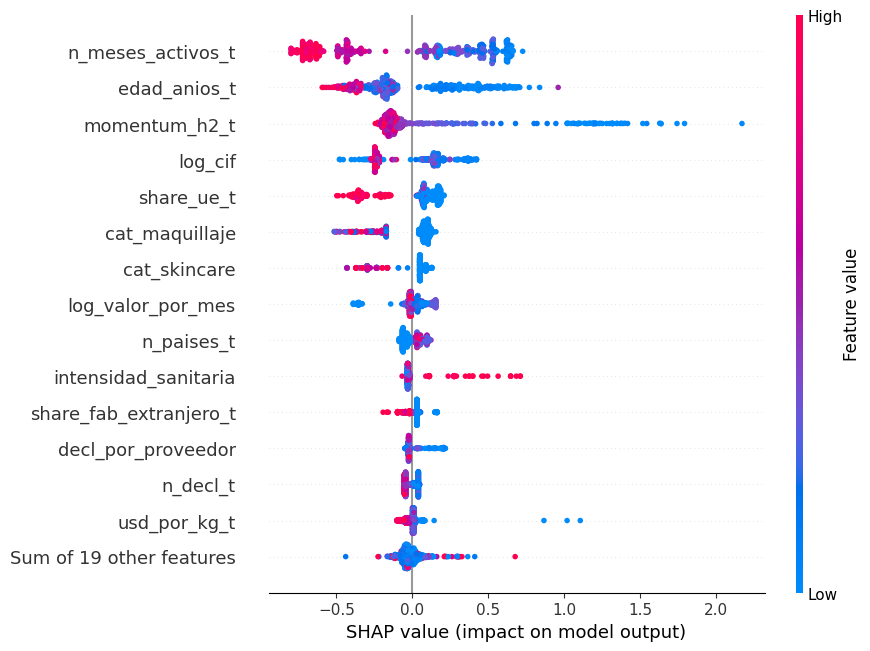

In [113]:
import shap

# Explicador SHAP para el modelo final Gradient Boosting
explainer = shap.TreeExplainer(gradient_boosting)

# Calcular valores SHAP sobre los datos de prueba 2024
shap_values = explainer(X_pru_arbol)

# Para clasificación binaria, analizar la clase de abandono (1)
if len(shap_values.shape) == 3:
    shap_values = shap_values[:, :, 1]

# Gráfico de importancia e impacto de las variables
shap.plots.beeswarm(shap_values, max_display=15)

### **18.3. Análisis de errores: ¿dónde se equivoca el modelo?**

In [114]:
# Recuperar las decisiones del modelo final
decision_gb = decisiones["Gradient Boosting"]

# Crear tabla de evaluación
errores = prueba[
    ["razon_social", "n_meses_activos_t"]
].copy()

errores["Probabilidad_abandono"] = prob_gb_2024
errores["Decision_modelo"] = pd.Series(
    decision_gb
).replace(NOMBRES).values

errores["Abandono_real"] = y_pru_array

# Identificar decisiones incorrectas
marcados = decision_gb != FIRMAR

errores["Tipo_error"] = "Acierto"

# Falso positivo: se identifica riesgo,
# pero el importador realmente no abandonó
errores.loc[
    marcados & (y_pru_array == 0),
    "Tipo_error"
] = "Falso positivo"

# Falso negativo: se recomienda firmar,
# pero el importador realmente abandonó
errores.loc[
    (~marcados) & (y_pru_array == 1),
    "Tipo_error"
] = "Falso negativo"

# Mostrar cantidad de cada resultado
print("Resumen de errores:")
display(
    errores["Tipo_error"].value_counts().to_frame("Cantidad")
)

# Mostrar ejemplos de errores
print("Falsos positivos:")
display(
    errores[errores["Tipo_error"] == "Falso positivo"].head(10)
)

print("Falsos negativos:")
display(
    errores[errores["Tipo_error"] == "Falso negativo"].head(10)
)

Resumen de errores:


,Cantidad
Tipo_error,
Acierto,258
Falso positivo,229
Falso negativo,16


Falsos positivos:


,razon_social,n_meses_activos_t,Probabilidad_abandono,Decision_modelo,Abandono_real,Tipo_error
3,LECOMPTES SAS,2,0.191469,No firmar,0,Falso positivo
5,FACTORES Y MERCADEO S. A.,9,0.102236,Firmar con garantías,0,Falso positivo
6,PROCLIN PHARMA S A,4,0.115124,Firmar con garantías,0,Falso positivo
7,TECNOFARMA COLOMBIA SAS,2,0.239350,No firmar,0,Falso positivo
12,IMCD COLOMBIA S.A.S.,4,0.221723,No firmar,0,Falso positivo
17,DISISTEMA LTDA,2,0.149498,Firmar con garantías,0,Falso positivo
22,LABORATORIOS FARMAVIC S.A.S.,2,0.181622,No firmar,0,Falso positivo
25,FOREVER LIVING PRODUCTS COLOMBIA LTDA,4,0.272175,No firmar,0,Falso positivo
33,PLUSS DENT LTDA,8,0.105821,Firmar con garantías,0,Falso positivo
36,MERCANTIL CONTINENTAL S.A.S.,4,0.281737,No firmar,0,Falso positivo


Falsos negativos:


,razon_social,n_meses_activos_t,Probabilidad_abandono,Decision_modelo,Abandono_real,Tipo_error
15,DROGUERIAS Y FARMACIAS CRUZ VERDE S A S,8,0.064978,Firmar,1,Falso negativo
23,JULVIP DENT LTDA,11,0.071854,Firmar,1,Falso negativo
51,TECNOSUR S.A.S.,11,0.055325,Firmar,1,Falso negativo
116,DEPOSITO DENTAL ALFOR LIMITADA,8,0.090166,Firmar,1,Falso negativo
121,INDUSTRIAS BISONTE S.A.,8,0.098364,Firmar,1,Falso negativo
124,LABORATORIOS RETY DE COLOMBIA S.A.S.,10,0.074468,Firmar,1,Falso negativo
152,AXON PHARMA SAS,6,0.073466,Firmar,1,Falso negativo
156,MESOESTETIC COLOMBIA EMPRESA UNIPERSONAL,5,0.094862,Firmar,1,Falso negativo
191,LABORATORIOS BIOPAS BELLE S.A.,9,0.086737,Firmar,1,Falso negativo
288,DEKA MEDIKA SAS,10,0.027347,Firmar,1,Falso negativo


In [115]:
# Analizar los resultados según las tres decisiones comerciales
errores["Resultado"] = np.select(
    [
        (errores["Decision_modelo"] == "Firmar") &
        (errores["Abandono_real"] == 0),

        (errores["Decision_modelo"] == "Firmar") &
        (errores["Abandono_real"] == 1),

        (errores["Decision_modelo"] == "Firmar con garantías") &
        (errores["Abandono_real"] == 0),

        (errores["Decision_modelo"] == "Firmar con garantías") &
        (errores["Abandono_real"] == 1),

        (errores["Decision_modelo"] == "No firmar") &
        (errores["Abandono_real"] == 0),

        (errores["Decision_modelo"] == "No firmar") &
        (errores["Abandono_real"] == 1)
    ],
    [
        "Firmar - Se mantuvo",
        "Firmar - Abandonó",
        "Garantías - Se mantuvo",
        "Garantías - Abandonó",
        "No firmar - Se mantuvo",
        "No firmar - Abandonó"
    ],
    default="Revisar"
)

display(errores["Resultado"].value_counts().to_frame("Cantidad"))

,Cantidad
Resultado,
Firmar - Se mantuvo,176
No firmar - Se mantuvo,166
No firmar - Abandonó,75
Garantías - Se mantuvo,63
Firmar - Abandonó,16
Garantías - Abandonó,7


### **18.4. ¿En qué perfiles se concentra el error del modelo?**

In [116]:
# 1. Seleccionar variables relevantes del análisis SHAP
variables_perfil = [
    "n_meses_activos_t",
    "n_decl_t",
    "log_cif",
    "decl_por_proveedor",
    "edad_anios_t",
    "momentum_h2_t",
    "usd_por_kg_t",
    "n_fabricantes_t",
    "n_proveedores_t",
    "log_valor_por_mes"
]

# 2. Conservar únicamente las variables disponibles
variables_perfil = [
    v for v in variables_perfil
    if v in X_pru_original.columns
]

# 3. Recuperar las variables originales sin duplicar columnas
columnas_nuevas = [
    v for v in variables_perfil
    if v not in errores.columns
]

perfil_errores = errores.join(
    X_pru_original[columnas_nuevas]
)

# 4. Calcular los promedios por tipo de resultado
resumen_perfiles = (
    perfil_errores
    .groupby("Resultado")[variables_perfil]
    .mean()
    .round(2)
)

print("Comparación de perfiles según el resultado del modelo:")
display(resumen_perfiles)

# 5. Mostrar la cantidad de importadores por grupo
print("Cantidad de importadores por grupo:")
display(
    perfil_errores["Resultado"]
    .value_counts()
    .to_frame("Cantidad")
)

Comparación de perfiles según el resultado del modelo:


,n_meses_activos_t,n_decl_t,log_cif,decl_por_proveedor,edad_anios_t,momentum_h2_t,usd_por_kg_t,n_fabricantes_t,n_proveedores_t,log_valor_por_mes
Resultado,,,,,,,,,,
Firmar - Abandonó,8.81,73.25,5.55,20.97,19.53,0.46,188.83,1.75,3.88,4.66
Firmar - Se mantuvo,10.29,327.41,6.02,80.62,20.56,0.55,55.87,6.86,4.72,5.02
Garantías - Abandonó,4.43,22.00,4.73,6.09,21.83,0.48,28.71,0.29,2.71,4.15
Garantías - Se mantuvo,6.54,22.86,5.19,13.92,16.87,0.60,42.23,1.48,2.43,4.42
No firmar - Abandonó,2.83,6.68,4.80,4.16,11.19,0.48,64.49,0.71,1.60,4.42
No firmar - Se mantuvo,3.49,6.86,4.84,4.29,11.99,0.55,147.23,1.11,1.73,4.36


Cantidad de importadores por grupo:


,Cantidad
Resultado,
Firmar - Se mantuvo,176
No firmar - Se mantuvo,166
No firmar - Abandonó,75
Garantías - Se mantuvo,63
Firmar - Abandonó,16
Garantías - Abandonó,7


# **19. Radar 2026: evaluación y selección de importadore**s

### **19.1	Entrenar el modelo final con los datos de 2023 y 2024**

In [117]:
# 1. Unir los datos históricos para el entrenamiento final
entrenamiento_final = pd.concat(
    [entrenamiento, prueba],
    ignore_index=True
)

X_ent_final_original = entrenamiento_final[
    NUMERICAS + CATEGORICAS
].copy()

y_ent_final = entrenamiento_final[OBJETIVO].astype(int)

# 2. Aprender la preparación con los datos de 2023 y 2024
prep_radar = aprender_preparacion(X_ent_final_original)

X_ent_final = aplicar_preparacion(
    X_ent_final_original,
    prep_radar,
    zscore=False
)

# 3. Preparar los datos de los importadores de 2025
X_radar_original = radar[
    NUMERICAS + CATEGORICAS
].copy()

X_radar = aplicar_preparacion(
    X_radar_original,
    prep_radar,
    zscore=False
)

# 4. Entrenar Gradient Boosting con los parámetros seleccionados
modelo_radar = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.03,
    max_depth=2,
    random_state=SEMILLA
)

modelo_radar.fit(X_ent_final, y_ent_final)

# 5. Verificar el entrenamiento
print("MODELO FINAL ENTRENADO CORRECTAMENTE")
print("Años utilizados: 2023 y 2024")
print("Importadores utilizados:", len(y_ent_final))
print("Importadores para el radar 2026:", len(X_radar))
print("Variables utilizadas:", X_ent_final.shape[1])
print("Tasa de abandono histórica:", round(y_ent_final.mean(), 3))


MODELO FINAL ENTRENADO CORRECTAMENTE
Años utilizados: 2023 y 2024
Importadores utilizados: 1000
Importadores para el radar 2026: 540
Variables utilizadas: 33
Tasa de abandono histórica: 0.206


### **19.2	Calcular la probabilidad de abandono de cada importador de 2025.**

In [118]:
# Probabilidad estimada de abandono durante 2026
prob_abandono_2026 = modelo_radar.predict_proba(X_radar)[:, 1]

# Construir tabla del radar
radar_2026 = radar[
    ["nit", "razon_social", "afinidad_seoru"]
].copy()

radar_2026["Probabilidad_abandono"] = prob_abandono_2026

# Índice de arraigo importador: probabilidad de permanencia
radar_2026["IAI"] = 100 * (1 - radar_2026["Probabilidad_abandono"])

# Ordenar de mayor a menor arraigo
radar_2026 = radar_2026.sort_values(
    "IAI", ascending=False
).reset_index(drop=True)

# Revisar resultados
print("Importadores evaluados:", len(radar_2026))
print("\nResumen de probabilidades e IAI:")
display(
    radar_2026[
        ["Probabilidad_abandono", "IAI", "afinidad_seoru"]
    ].describe().round(3)
)

print("\nPrimeros 10 importadores por IAI:")
display(radar_2026.head(10))


Importadores evaluados: 540

Resumen de probabilidades e IAI:


,Probabilidad_abandono,IAI,afinidad_seoru
count,540.000,540.000,540.000
mean,0.191,80.873,0.047
std,0.148,14.817,0.127
min,0.020,21.546,0.000
25%,0.072,71.506,0.000
50%,0.143,85.705,0.000
75%,0.285,92.778,0.000
max,0.785,98.045,1.000



Primeros 10 importadores por IAI:


,nit,razon_social,afinidad_seoru,Probabilidad_abandono,IAI
0,860000751.0,HENKEL COLOMBIANA S.A S,0.086957,0.019555,98.044508
1,890905032.0,PREBEL S.A. BIC,0.040000,0.019555,98.044508
2,860002518.0,UNILEVER ANDINA COLOMBIA LTDA,0.175258,0.026017,97.398312
3,800205416.0,PERCOS S. A.,0.120000,0.026907,97.309286
4,900017447.0,FALABELLA DE COLOMBIA S A,0.050000,0.027007,97.299279
5,830007716.0,AMWAY COLOMBIA,0.142857,0.027092,97.290750
6,830023671.0,ORIFLAME DE COLOMBIA S.A.,0.063492,0.028004,97.199594
7,802019447.0,SESDERMA COLOMBIA S.A.,0.218750,0.028906,97.109419
8,900832629.0,BLUSH-BAR S.A.S,0.055000,0.028961,97.103930
9,900990465.0,ELCA COSMeTICOS COLOMBIA S.A.S.,0.103448,0.028961,97.103930


### **19.3	Calcular el IAI y asignar las tres recomendaciones: firmar, firmar con garantías y no firmar.**

In [119]:

# Umbrales seleccionados mediante validación cruzada
U1_GB = 0.10
U2_GB = 0.16

# Asignar recomendación según probabilidad de abandono
radar_2026["Recomendacion"] = np.select(
    [
        radar_2026["Probabilidad_abandono"] <= U1_GB,
        radar_2026["Probabilidad_abandono"] <= U2_GB
    ],
    [
        "Firmar",
        "Firmar con garantías"
    ],
    default="No firmar"
)

# Resumir cantidad de importadores por recomendación
print("Distribución de recomendaciones:")
display(
    radar_2026["Recomendacion"]
    .value_counts()
    .to_frame("Cantidad")
)

# Calcular porcentaje por categoría
distribucion = (
    radar_2026["Recomendacion"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame("Porcentaje")
)

display(distribucion)

# Mostrar ejemplos de cada recomendación
print("Ejemplos de importadores por recomendación:")
display(
    radar_2026.groupby("Recomendacion").head(3)[
        [
            "nit",
            "razon_social",
            "Probabilidad_abandono",
            "IAI",
            "afinidad_seoru",
            "Recomendacion"
        ]
    ]
)


Distribución de recomendaciones:


,Cantidad
Recomendacion,
No firmar,253
Firmar,204
Firmar con garantías,83


,Porcentaje
Recomendacion,
No firmar,46.85
Firmar,37.78
Firmar con garantías,15.37


Ejemplos de importadores por recomendación:


,nit,razon_social,Probabilidad_abandono,IAI,afinidad_seoru,Recomendacion
0,860000751.0,HENKEL COLOMBIANA S.A S,0.019555,98.044508,0.086957,Firmar
1,890905032.0,PREBEL S.A. BIC,0.019555,98.044508,0.040000,Firmar
2,860002518.0,UNILEVER ANDINA COLOMBIA LTDA,0.026017,97.398312,0.175258,Firmar
204,900978438.0,PRIMKO SAS,0.100116,89.988389,0.000000,Firmar con garantías
205,901395448.0,CANM DISTRIBUIDORA SAS,0.100355,89.964531,0.000000,Firmar con garantías
206,900183077.0,MEDITEK ERGO S.A.S.,0.101460,89.854039,0.000000,Firmar con garantías
287,901370203.0,OPERFEL COLOMBIA SAS,0.162202,83.779820,0.000000,No firmar
288,900967599.0,COMERCIALIZADORA BILU SAS,0.162298,83.770161,0.000000,No firmar
289,890913400.0,DENTALES ANTIOQUIA S.A.S.,0.163432,83.656794,0.000000,No firmar


### **19.4	Seleccionar los 20 candidatos para diligencia debida, combinando riesgo y afinidad con Seoru.**

In [120]:

# 1. Seleccionar importadores elegibles para avanzar
elegibles = radar_2026[
    radar_2026["Recomendacion"].isin(
        ["Firmar", "Firmar con garantías"]
    )
].copy()

# 2. Ordenar por afinidad con Seoru y, en segundo lugar, por IAI
candidatos_20 = elegibles.sort_values(
    ["afinidad_seoru", "IAI"],
    ascending=False
).head(20).copy()

# 3. Asignar posición en el ranking
candidatos_20.insert(
    0,
    "Ranking",
    range(1, len(candidatos_20) + 1)
)

# 4. Añadir una explicación de la selección
candidatos_20["Criterio_seleccion"] = (
    "Alta afinidad con Seoru y arraigo suficiente"
)

# 5. Mostrar los candidatos seleccionados
columnas_mostrar = [
    "Ranking",
    "nit",
    "razon_social",
    "Probabilidad_abandono",
    "IAI",
    "afinidad_seoru",
    "Recomendacion",
    "Criterio_seleccion"
]

print("Candidatos seleccionados:", len(candidatos_20))
display(candidatos_20[columnas_mostrar].round(3))

# 6. Resumen de los candidatos
print("\nResumen de los 20 candidatos:")
display(
    candidatos_20[
        ["IAI", "Probabilidad_abandono", "afinidad_seoru"]
    ].mean().to_frame("Promedio").round(3)
)


Candidatos seleccionados: 20


,Ranking,nit,razon_social,Probabilidad_abandono,IAI,afinidad_seoru,Recomendacion,Criterio_seleccion
130,1,901079591.0,INVERSIONES PAMBU SAS,0.069,93.110,1.000,Firmar,Alta afinidad con Seoru y arraigo suficiente
59,2,830012269.0,GALDERMA DE COLOMBIA S.A.,0.045,95.542,0.714,Firmar,Alta afinidad con Seoru y arraigo suficiente
122,3,900972597.0,DOTERRA COLOMBIA LLC SUCURSAL COLOMBIA,0.066,93.421,0.667,Firmar,Alta afinidad con Seoru y arraigo suficiente
151,4,900997817.0,MUNDIAL DE MERCANCIAS S.A.S.,0.077,92.339,0.600,Firmar,Alta afinidad con Seoru y arraigo suficiente
104,5,860074450.0,QUALA S.A.,0.060,93.983,0.500,Firmar,Alta afinidad con Seoru y arraigo suficiente
196,6,900680675.0,FRANQUICIAS DIRECT TV S.A.S,0.097,90.307,0.500,Firmar,Alta afinidad con Seoru y arraigo suficiente
266,7,901306962.0,MIRRORS IN THE ATTIC S.A.S.,0.143,85.742,0.500,Firmar con garantías,Alta afinidad con Seoru y arraigo suficiente
20,8,900480569.0,JERONIMO MARTINS COLOMBIA S.A.S.,0.033,96.651,0.444,Firmar,Alta afinidad con Seoru y arraigo suficiente
25,9,900482118.0,COMERCIALIZADORA LYON SAS,0.035,96.500,0.438,Firmar,Alta afinidad con Seoru y arraigo suficiente
69,10,900252067.0,"NU SKIN COLOMBIA, INC.",0.048,95.235,0.400,Firmar,Alta afinidad con Seoru y arraigo suficiente



Resumen de los 20 candidatos:


,Promedio
IAI,93.173
Probabilidad_abandono,0.068
afinidad_seoru,0.457


###**19.5	Calcular el valor económico del radar frente a la regla simple**


In [121]:

# Recuperar los costos obtenidos en la evaluación de 2024
costo_radar = comparacion.loc[
    "Gradient Boosting", "Costo por 100"
]

costo_regla = comparacion.loc[
    "Regla simple", "Costo por 100"
]

# Calcular el ahorro del modelo frente a la regla simple
ahorro_radar = costo_regla - costo_radar

porcentaje_ahorro = (
    ahorro_radar / costo_regla * 100
)

# Construir tabla comparativa
valor_radar = pd.DataFrame({
    "Costo por cada 100 importadores (US$)": [
        costo_regla,
        costo_radar
    ]
}, index=[
    "Regla simple",
    "Gradient Boosting (Radar)"
])

display(valor_radar.round(0))

print("Ahorro del radar frente a la regla simple:")
print("US$", round(ahorro_radar))

print("Reducción porcentual del costo:")
print(round(porcentaje_ahorro, 2), "%")


,Costo por cada 100 importadores (US$)
Regla simple,2793241.0
Gradient Boosting (Radar),2862823.0


Ahorro del radar frente a la regla simple:
US$ -69583
Reducción porcentual del costo:
-2.49 %


# **20. Despliegue: exportar el modelo final a la plantilla de la aplicación**

El modelo del radar (sección 19) se reconstruye como un *Pipeline* de scikit-learn con exactamente la misma preparación (mediana, recorte p1–p99, logaritmo de los conteos y variables dummy) y los mismos parámetros de Gradient Boosting. Así la aplicación recibe los datos tal como vienen. Si la carpeta de la app no está en Drive, la celda construye y verifica el pipeline y omite la exportación.

In [122]:
import os
import sys
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder

# Ruta de la carpeta de la app en Drive (solo hace falta para exportar; si no existe, la celda igual corre)
carpeta_app = "/content/drive/MyDrive/glowup_app"

# 1. Pipeline = preparación del cuaderno + Gradient Boosting elegido
num_ent = X_ent_final_original[NUMERICAS]
medianas_ent = num_ent.median()
num_ent = num_ent.fillna(medianas_ent)
p01_ent, p99_ent = num_ent.quantile(0.01), num_ent.quantile(0.99)

pasos_columnas = []
for col in NUMERICAS:
    pasos = [("imputar", SimpleImputer(strategy="median")),
             ("recortar", FunctionTransformer(np.clip, kw_args={"a_min": float(p01_ent[col]), "a_max": float(p99_ent[col])},
                                              feature_names_out="one-to-one"))]
    if col in CON_LOG:   # log(1 + x): para los árboles da los mismos cortes que log10(1 + x)
        pasos.append(("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")))
    pasos_columnas.append((col, Pipeline(pasos), [col]))
pasos_columnas.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAS))

pipeline_radar = Pipeline([
    ("preparacion", ColumnTransformer(pasos_columnas, verbose_feature_names_out=False)),
    ("modelo", GradientBoostingClassifier(n_estimators=200, learning_rate=0.03, max_depth=2, random_state=SEMILLA)),
])
pipeline_radar.fit(X_ent_final_original, y_ent_final)

# Comprobación: el pipeline da las mismas probabilidades que modelo_radar (sección 19)
prob_pipeline_2026 = pipeline_radar.predict_proba(radar[NUMERICAS + CATEGORICAS])[:, 1]
print("Diferencia máxima con modelo_radar:", np.abs(prob_pipeline_2026 - prob_abandono_2026).max())

# 2. Valor frente a la regla simple en la prueba 2024 (mismas muestras bootstrap de la sección 15)
costo_gb_2024 = costo_por_100(y_pru_array, decisiones["Gradient Boosting"])
costo_regla_2024 = costo_por_100(y_pru_array, decisiones["Regla simple"])
ahorro_boot = costos_bootstrap(decisiones["Regla simple"]) - costos_bootstrap(decisiones["Gradient Boosting"])
VP_gb = ((decisiones["Gradient Boosting"] != FIRMAR) & (y_pru_array == 1)).sum()
VP_regla = ((decisiones["Regla simple"] != FIRMAR) & (y_pru_array == 1)).sum()

metricas_app = {
    "costo_modelo": float(costo_gb_2024),
    "costo_regla": float(costo_regla_2024),
    "regla_simple": "No firmar con quien importa en menos de 7 meses al año; firmar con los demás",
    "unidad_costo": "en US$ por cada 100 importadores evaluados (prueba 2024, modelo entrenado con 2023)",
    "intervalo_diferencia": [float(np.percentile(ahorro_boot, 2.5)), float(np.percentile(ahorro_boot, 97.5))],
    "pct_muestras_modelo_gana": float((ahorro_boot > 0).mean()),
    "auc_modelo": float(roc_auc_score(y_pru_array, prob_gb_2024)),
    "auc_regla": float(roc_auc_score(y_pru_array, -prueba["n_meses_activos_t"])),
    "sensibilidad_modelo": float(VP_gb / (y_pru_array == 1).sum()),
    "sensibilidad_regla": float(VP_regla / (y_pru_array == 1).sum()),
    "abandonos_que_firma_modelo": int(((decisiones["Gradient Boosting"] == FIRMAR) & (y_pru_array == 1)).sum()),
    "abandonos_que_firma_regla": int(((decisiones["Regla simple"] == FIRMAR) & (y_pru_array == 1)).sum()),
    "importadores_prueba": int(len(y_pru_array)),
}

# 3. Tabla del radar 2026 para la app (condiciones de uso: nada de valores exactos de LegisComex)
tabla_app = radar.copy()
tabla_app["nit"] = tabla_app["nit"].astype("int64").astype(str)
es_persona = tabla_app["razon_social"].astype(str).str.upper().str.contains("PERSONA NATURAL")
tabla_app.loc[es_persona, "razon_social"] = "Persona natural (dato protegido)"   # Ley 1581 de 2012
tabla_app.loc[es_persona, "nit"] = ["PN-" + str(i + 1) for i in range(es_persona.sum())]

NOMBRES_CAT = {"cat_skincare": "Cuidado de la piel", "cat_maquillaje": "Maquillaje", "cat_capilar": "Capilar",
               "cat_fragancia": "Fragancias", "cat_corporal": "Corporal", "cat_unas": "Uñas", "cat_solar": "Solar",
               "cat_oral": "Cuidado oral", "cat_desodorante": "Desodorantes", "cat_hombre": "Hombre"}
cats = tabla_app[list(NOMBRES_CAT)].fillna(0)
tabla_app["producto_principal"] = np.where(cats.max(axis=1) > 0, cats.idxmax(axis=1).map(NOMBRES_CAT),
                                           "Sin notificaciones nuevas")
tabla_app["rango_meses_activos"] = pd.cut(tabla_app["n_meses_activos_t"], [0, 3, 6, 9, 12],
                                          labels=["1 a 3 meses", "4 a 6 meses", "7 a 9 meses", "10 a 12 meses"]).astype(str)
tabla_app["afinidad_seoru_pct"] = (100 * tabla_app["afinidad_seoru"]).round(1)
tabla_app["antiguedad_anios"] = tabla_app["edad_anios_t"].round(0)
tabla_app["tiene_notificaciones_invima"] = np.where(tabla_app["tiene_invima"] == 1, "Sí", "No")

# Los 20 candidatos para diligencia debida: el mismo criterio de la sección 19.4
tabla_app["_p"] = prob_pipeline_2026
tabla_app["_iai"] = 100 * (1 - tabla_app["_p"])
elegibles_app = tabla_app[tabla_app["_p"] < U2_GB].sort_values(["afinidad_seoru", "_iai"], ascending=False)
tabla_app["ranking_diligencia"] = np.nan
tabla_app.loc[elegibles_app.index[:20], "ranking_diligencia"] = range(1, 21)

ETIQUETAS_APP = {
    "nit": "NIT", "razon_social": "Importador", "log_cif": "Valor importado al año",
    "n_decl_t": "Número de declaraciones", "n_proveedores_t": "Número de proveedores",
    "n_paises_t": "Países de origen", "n_meses_activos_t": "Meses con importaciones",
    "share_china_t": "Participación de China", "share_ue_t": "Participación de la UE",
    "share_usa_t": "Participación de EE. UU.", "momentum_h2_t": "Peso del segundo semestre",
    "usd_por_kg_t": "Precio por kilo", "reg_t": "Notificaciones INVIMA nuevas",
    "reg_crec": "Crecimiento de notificaciones", "share_fab_extranjero_t": "Fabricantes extranjeros (proporción)",
    "n_fabricantes_t": "Número de fabricantes", "cat_skincare": "Proporción en cuidado de la piel",
    "cat_maquillaje": "Proporción en maquillaje", "cat_capilar": "Proporción capilar",
    "cat_corporal": "Proporción corporal", "cat_solar": "Proporción solar",
    "n_categorias_t": "Categorías de producto", "edad_anios_t": "Antigüedad de la empresa (años)",
    "camara_bogota": "Matrícula en Bogotá (1 = sí)", "intensidad_sanitaria": "Intensidad sanitaria",
    "log_valor_por_mes": "Valor por mes activo", "decl_por_proveedor": "Declaraciones por proveedor",
    "afinidad_seoru": "Afinidad con Seoru", "forma": "Forma jurídica", "grupo_actividad": "Actividad económica",
}

# Variables que vienen de LegisComex: en las razones se nombran, pero nunca se muestra su valor
DE_LEGISCOMEX = ["log_cif", "n_decl_t", "n_proveedores_t", "n_paises_t", "n_meses_activos_t", "share_china_t",
                 "share_ue_t", "share_usa_t", "momentum_h2_t", "usd_por_kg_t", "intensidad_sanitaria",
                 "log_valor_por_mes", "decl_por_proveedor"]

# 4. Exportar a la carpeta de la app (solo si está disponible)
if not os.path.isdir(carpeta_app):
    print("No se encontró la carpeta de la app en", carpeta_app)
    print("Se omitió la exportación. El modelo publicado en la app es este mismo pipeline (diferencia 0.0 arriba).")
else:
    sys.path.append(carpeta_app)
    from exportar import exportar
    exportar(
        modelo=pipeline_radar,
        X_entrenamiento=X_ent_final_original,
        umbrales=[U1_GB, U2_GB],
        decisiones=["Firmar", "Firmar con garantías", "No firmar"],
        metricas=metricas_app,
        evento="abandono",
        tabla_resultados=tabla_app,
        probabilidad_resultados=prob_pipeline_2026,
        columna_id="nit",
        columnas_a_mostrar=["razon_social", "ranking_diligencia", "afinidad_seoru_pct", "producto_principal",
                            "cif_t", "rango_meses_activos", "antiguedad_anios", "grupo_actividad",
                            "tiene_notificaciones_invima"],
        etiquetas=ETIQUETAS_APP,
        columnas_ocultas=DE_LEGISCOMEX,
        columnas_en_rangos={"cif_t": {"cortes": [0, 100000, 500000, 2000000, 10000000], "prefijo": "US$"}},
    )

Diferencia máxima con modelo_radar: 0.0
No se encontró la carpeta de la app en /content/drive/MyDrive/glowup_app
Se omitió la exportación. El modelo publicado en la app es este mismo pipeline (diferencia 0.0 arriba).


Esa celda demuestra que el modelo de la app es idéntico al del cuaderno (diferencia 0). La exportación a la plantilla se hizo una vez y esos archivos están en el repositorio